In [1]:
%pip install snntorch
import torch
import torch.nn as nn
import glob
from torch.nn.functional import cross_entropy
import torch.nn.functional as F
import snntorch as snn
from snntorch import spikegen
from snntorch import surrogate
import glob
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import gc
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
 
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

class LOBDayDataset(Dataset):
    """Loads a single day file from the FI-2010 dataset without cross-day leakage"""
    def __init__(self, filepath, window_size=30, stride=5, delta_threshold=0.005):
        
        data = np.loadtxt(filepath)
        features = data[:144, :].T  # features
        labels = data[146, :].T - 1 # labels (we map them from {1, 2, 3...} to {0, 1, 2, 3.....})
        del data

        features_tensor = torch.from_numpy(features).float()
        labels_tensor = torch.from_numpy(labels).long()
        del features, labels

        # spike encoding using delta modulation see https://snntorch.readthedocs.io/en/latest/tutorials/legacy/tutorial_1_old.html#delta-modulation
        spike = spikegen.delta(features_tensor, threshold=delta_threshold, padding=True, off_spike=True)
        spikes_pos = torch.where(spike > 0, spike, torch.zeros_like(spike))
        spikes_neg = torch.where(spike < 0, torch.abs(spike), torch.zeros_like(spike))
        del spike, features_tensor

        # inputs <= spike_pos + spike_neg
        inputs = torch.cat((spikes_pos, spikes_neg), dim=1).half() 
        del spikes_pos, spikes_neg

        
        
        # we slice the inputs into sequence windows 
        self.X, self.Y = self._create_sequences(inputs, labels_tensor, window_size, stride)
        del inputs, labels_tensor
        gc.collect()
    
    # create sequence of the inputs based on window_size and stride
    def _create_sequences(self, inputs, labels, window_size, stride):
        X, Y = [], []
        for i in range(0, len(inputs) - window_size, stride):
            X.append(inputs[i : i + window_size])
            Y.append(labels[i + window_size - 1])
        return torch.stack(X), torch.stack(Y)

    def __len__(self):
        return len(self.Y)

    def __getitem__(self, idx):
        return self.X[idx].float(), self.Y[idx]

# our previous approach was to train the model on all the training days previous to fold_idx,
# ex: if fold_idx = 3, we  train on day 1, 2, 3 all of the file concated, however what i did not count on
# is that the files are already concated so day 3 contains all the previous days data + the new data of day 3 
def get_anchored_fold_loaders(fold_idx, train_files, test_files, batch_size=256):
     print(
         f'\n ***** fold {fold_idx + 1} / 9 training on:'
         f'{train_files[fold_idx].split('/')[-1]} and testing on:'
         f'{test_files[fold_idx].split("/")[-1]}'
     )
     
     train_dataset = LOBDayDataset(train_files[fold_idx])
     test_dataset = LOBDayDataset(test_files[fold_idx])
     
     train_loader = DataLoader(train_dataset,
                               batch_size=batch_size,
                               shuffle=False,
                               pin_memory=True,
                               num_workers=2)
     test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=True)
     return train_loader, test_loader, train_dataset

In [ ]:

def weights(device, labels, smoothing=.15):
    class_counts = torch.bincount(labels.long())
    total_samples = len(labels)
    
    smoothed_c = class_counts.float() + (smoothing * total_samples / len(class_counts))
    dynamic_weights = total_samples / (len(class_counts) * smoothed_c)
    print(dynamic_weights)
    return dynamic_weights.to(device=device)

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        super().__init__()
        self.alpha = alpha  # weights
        self.gamma = gamma 
        self.reduction = reduction
    
    def forward(self, logits, targets):
        ce_loss = cross_entropy(logits, targets, reduction='none', weight=self.alpha)
        pt = torch.exp(-ce_loss)
        focal_weight = (1 - pt) ** self.gamma  
        loss = focal_weight * ce_loss
        
        if self.reduction == 'mean':
            return loss.mean()
        return loss.sum()

class STEQuantize(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, num_levels):
        if num_levels is None or num_levels <= 1:
            return x
        scaled = x * (num_levels - 1)
        quantized = torch.round(scaled)
        return quantized / (num_levels - 1)

    @staticmethod
    def backward(ctx, grad_output):
        return grad_output, None

# Hardware-aware RRAM crossbar with: 
# Differential conductance mapping 
# Stuck at fauls (SAF)
# Cycle-to-cyle variation
# Device-to-Device variation
# Retention Drift    
class MemristorCrossbar(nn.Module):
    def __init__(self, in_features, out_features, num_levels=16, saf_rate=0.03, noise_std=0.05, 
                d2d_std=0.05,
                drift_rate=0.002,
                force_ideal=False,
                force_noise_eval=False
                ):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        
        if force_ideal:
            num_levels = 0
            saf_rate = 0.0
            noise_std = 0.0
            d2d_std = 0.0
            drift_rate = 0.0
            
        self.num_levels = num_levels
        self.noise_std = noise_std
        self.d2d_std = d2d_std
        self.force_ideal = force_ideal
        self.drift_rate = drift_rate
        self.force_noise_eval = force_noise_eval
        self.weight = nn.Parameter(torch.Tensor(out_features, in_features))
        self.bias = nn.Parameter(torch.Tensor(out_features))
        
        print(f"params memristor: {num_levels }, {saf_rate}, {noise_std}, {d2d_std}, {drift_rate}")
        nn.init.normal_(self.weight, mean=0.0, std=0.05)
        nn.init.zeros_(self.bias)

      
        self.register_buffer("saf_pos_lrs", torch.rand(out_features, in_features) < (saf_rate / 2))  # stuck-at-low resistance state ; stuck at one
        self.register_buffer("saf_pos_hrs", torch.rand(out_features, in_features) < (saf_rate / 2))   # stuck-at-high resistance state ; stuck at 0
        self.register_buffer("saf_neg_lrs", torch.rand(out_features, in_features) < (saf_rate / 2))
        self.register_buffer("saf_neg_hrs",torch.rand(out_features, in_features) < (saf_rate / 2))

       # Device-to-Device variation D2D
        self.register_buffer("d2d_pos", torch.clamp( 1.0 + torch.randn(out_features, in_features) * d2d_std, 0.7, 1.3))
        self.register_buffer("d2d_neg", torch.clamp( 1.0 + torch.randn(out_features, in_features) * d2d_std, 0.7, 1.3))

    def get_hardware_weights(self):

        # weights normalized
        weight_scale = torch.max(torch.abs(self.weight)).detach().clamp(min=1e-5)
        w_norm = torch.clamp(self.weight / weight_scale, -1.0, 1.0)
        g_pos = (w_norm + 1.0) / 2.0
        g_neg = (1.0 - w_norm) / 2.0
        
        g_pos *= self.d2d_pos
        g_neg *= self.d2d_neg
        
        g_pos = torch.clamp(g_pos, 0.0, 1.0)
        g_neg = torch.clamp(g_neg, 0.0, 1.0)

        # stuch at faults (SAF)
        g_pos = torch.where(self.saf_pos_lrs, torch.ones_like(g_pos), g_pos)
        g_pos = torch.where(self.saf_pos_hrs, torch.zeros_like(g_pos), g_pos)
        g_neg = torch.where(self.saf_neg_lrs, torch.ones_like(g_neg), g_neg)
        g_neg = torch.where(self.saf_neg_hrs, torch.zeros_like(g_neg), g_neg)
        # qunatization
        g_pos_q = STEQuantize.apply(g_pos, self.num_levels)
        g_neg_q = STEQuantize.apply(g_neg, self.num_levels)
       
        #C2C cycle to cycle
        if (self.training or self.force_noise_eval) and self.noise_std > 0:
            g_pos_q = torch.clamp(g_pos_q + torch.randn_like(g_pos_q) * self.noise_std, 0.0, 1.0)
            g_neg_q = torch.clamp(g_neg_q + torch.randn_like(g_neg_q) * self.noise_std, 0.0, 1.0)

        # retention drift
        if not self.training:
            drift = torch.exp(torch.full_like(g_pos_q, -self.drift_rate))
            g_pos_q *= drift
            g_neg_q *= drift
        w_hardware = (g_pos_q - g_neg_q) * weight_scale
        
        return w_hardware

    def forward(self, x):
        w_hardware = self.get_hardware_weights()
        return F.linear(x, w_hardware, self.bias)
    
    
class MSNN(nn.Module):
    """hardware-constrained MSNN and tarcking spike metrics"""
    def __init__(self, num_inputs=288, num_hidden=128, num_outputs=3, beta=0.9, num_levels=16, saf_rate=0.03, noise_std=0.05, force_ideal=False, force_noise_eval=False):
        super().__init__()
        spike_grad = surrogate.fast_sigmoid(slope=25)
        
        self.fc1 = MemristorCrossbar(num_inputs, num_hidden, num_levels, saf_rate, noise_std, force_ideal=force_ideal, force_noise_eval=force_noise_eval)
        self.lif1 = snn.Leaky(threshold=0.5, beta=beta, spike_grad=spike_grad, reset_mechanism="subtract")
        self.drop = nn.Dropout(0.3) 
        
        self.fc2 = MemristorCrossbar(num_hidden, num_outputs, num_levels, saf_rate, noise_std, force_ideal=force_ideal, force_noise_eval=force_noise_eval)
        self.lif2 = snn.Leaky(threshold=1.0, beta=beta, spike_grad=spike_grad, reset_mechanism="subtract")
        
        # keep track of spike counts
        self.spike_counts = {"layer1": 0.0, "layer2": 0.0, "total_steps": 0}

    def reset_spike_metrics(self):
        self.spike_counts = {"layer1": 0.0, "layer2": 0.0, "total_steps": 0}

    def forward(self, x):
        # adjust the input shame from (batch, time, featurres) ->> (time, batch, features)
        x = x.permute(1, 0, 2)
        batch_size = x.shape[1]
        time_steps = x.shape[0]
        
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
        
        # input current is calculated in a single vectorized operation
        cur1_all = self.fc1(x)
        
        # Cache Layer 2 hardware matrix weights for this specific forward timeline execution block
        w_phys2 = self.fc2.get_hardware_weights()
        bias2 = self.fc2.bias
        
        for step in range(time_steps):
            spk1, mem1 = self.lif1(cur1_all[step], mem1)
            spk1_dropped = self.drop(spk1)
            
            # record layer 1 spike track
            if not self.training:
                self.spike_counts["layer1"] += spk1.detach().sum().item()
            
            cur2 = F.linear(spk1_dropped, w_phys2, bias2)
            spk2, mem2 = self.lif2(cur2, mem2)
            
            # record layer 2 spike track
            if not self.training:
                self.spike_counts["layer2"] += spk2.detach().sum().item()
                
        if not self.training:
            self.spike_counts["total_steps"] += (batch_size * time_steps)
            
        return mem2

X

In [4]:
def compute_hardware_metrics(data_loader, net, device, window_size=30):
    """evaluates the model and computes hardware metrics etc...
        window_size is a must, unless if its 30
    """
    net.eval()
    net.reset_spike_metrics()
    
    correct = 0
    total = 0
    
    with torch.no_grad():
        for data, targets in data_loader:
            data = data.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True).long()
            logits = net(data)
            preds = logits.argmax(dim=1)
            
            correct += (preds == targets).sum().item()
            total += targets.size(0)
            
    # calculates sparsity metrics
    total_samples_processed = net.spike_counts["total_steps"] / window_size  
    total_neuron_steps_l1 = net.spike_counts["total_steps"] * net.fc1.out_features
    total_neuron_steps_l2 = net.spike_counts["total_steps"] * net.fc2.out_features
    
    l1_sparsity = net.spike_counts["layer1"] / max(1, total_neuron_steps_l1)
    l2_sparsity = net.spike_counts["layer2"] / max(1, total_neuron_steps_l2)
    
    accuracy = correct / total
    
    print("\n*** extracted hardware metrics ***")
    print(f"accuracy: {accuracy*100:.2f}%")
    print(f"layer 1 firing density : {l1_sparsity*100:.3f}% spikes/neuron/step")
    print(f"layer 2 firing density : {l2_sparsity*100:.3f}% spikes/neuron/step")
    print(f"total spikes emitted per sequence window ({window_size}): {(net.spike_counts['layer1'] + net.spike_counts['layer2']) / max(1, total_samples_processed):.2f}")
    
    return {
        "accuracy": accuracy,
        "l1_sparsity": l1_sparsity,
        "l2_sparsity": l2_sparsity,
    }


In [6]:
!mkdir ./drive/MyDrive/data/noisy

mkdir: cannot create directory ‘./drive/MyDrive/data/noisy’: File exists


In [ ]:
import torch
import numpy as np
import os

num_epochs = 30   
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")

# update with ur own paths 
train_files = sorted(glob.glob(
    "./drive/MyDrive/data/published/BenchmarkDatasets/BenchmarkDatasets/BenchmarkDatasets/NoAuction/NoAuction_MinMax/NoAuction_MinMax_Training/Train_Dst_NoAuction_MinMax_CF_*.txt"
))
test_files = sorted(glob.glob(
    "./drive/MyDrive/data/published/BenchmarkDatasets/BenchmarkDatasets/BenchmarkDatasets/NoAuction/NoAuction_MinMax/NoAuction_MinMax_Testing/Test_Dst_NoAuction_MinMax_CF_*.txt"
))

output_dir = './drive/MyDrive/data/noisy'
os.makedirs(output_dir, exist_ok=True)
fold_summary_metrics = []


# loop across all 9 files
for fold_idx in range(9):
    print("\n" + "*"*70)
    print(f"* anchord fold  {fold_idx + 1} / 9 *")
    print("*"*70)
    torch.manual_seed(123)
    net = MSNN(
        num_inputs=288, 
        num_hidden=128, 
        num_outputs=3, 
        beta=0.9, 
        num_levels=16, 
        saf_rate=0.03, 
        noise_std=0.05,
        force_ideal=False,
        force_noise_eval=True
    ).to(device)


    # get the needed fold time (based on fold_idx)
    train_loader, test_loader, fold_train_dataset = get_anchored_fold_loaders(
        fold_idx=fold_idx, 
        train_files=train_files, 
        test_files=test_files, 
        batch_size=256
    )
    
    if isinstance(fold_train_dataset, torch.utils.data.ConcatDataset):
        active_labels = torch.cat([ds.Y for ds in fold_train_dataset.datasets])
    else:
        active_labels = fold_train_dataset.Y
        
    w = weights(device=device, labels=active_labels)
    loss_fn = FocalLoss(alpha=w, gamma=2)
    
   
    num_epochs_per_fold = 20  
    optimizer = torch.optim.Adam(net.parameters(), lr=3e-4, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs_per_fold, eta_min=1e-6)
    
    best_fold_acc = 0.0
    patience_counter = 0
    patience = 4
    
    # training loop
    for epoch in range(num_epochs_per_fold):
        net.train()
        epoch_loss = 0.0
        
        for batch_idx, (data, targets) in enumerate(train_loader):
            data = data.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True).long()
            
            optimizer.zero_grad(set_to_none=True)
            logits = net(data)
            loss_val = loss_fn(logits, targets)
            
            loss_val.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
            optimizer.step()
            
            epoch_loss += loss_val.item()
            
        scheduler.step()
        avg_loss = epoch_loss / len(train_loader)
        
        net.eval()
        with torch.no_grad():
            val_correct = 0
            val_total = 0
            for val_data, val_targets in test_loader:
                val_data = val_data.to(device, non_blocking=True)
                val_targets = val_targets.to(device, non_blocking=True).long()
                
                val_preds = net(val_data).argmax(dim=1)
                val_correct += (val_preds == val_targets).sum().item()
                val_total += val_targets.size(0)
            current_val_acc = val_correct / max(1, val_total)
            
        print(f"Fold {fold_idx+1} | Epoch [{epoch+1}/{num_epochs_per_fold}] | Loss: {avg_loss:.4f} | Current Test Acc: {current_val_acc*100:.2f}%")
        
        if current_val_acc > best_fold_acc:
            best_fold_acc = current_val_acc
            patience_counter = 0
            torch.save(net.state_dict(), os.path.join(output_dir, f'model_{fold_idx+1}.pt'))
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("↳ Early stopping fold fine-tuning profile.")
                break
                
    # get hardware info on this fold 
    print(f"\n--- compiling hardware metrics for fold: {fold_idx + 1} ---") 
    checkpoint_file = os.path.join(output_dir, f'model_{fold_idx+1}.pt')
    net.load_state_dict(torch.load(checkpoint_file, map_location=device, weights_only=True))
    
    total_input_sparsity = 0.0
    num_batches = 0
    with torch.no_grad():
        for val_data, _ in test_loader:
            val_data = val_data.to(device, non_blocking=True)
            batch_density = val_data.float().mean().item()             
            total_input_sparsity += batch_density
            num_batches += 1
            
    fold_input_sparsity = total_input_sparsity / num_batches
    
    fold_profile = compute_hardware_metrics(test_loader, net, device)
    fold_summary_metrics.append({
        "fold": fold_idx + 1,
        "accuracy": fold_profile["accuracy"],
        "l1_sparsity": fold_profile["l1_sparsity"],
        "l2_sparsity": fold_profile["l2_sparsity"],
        "input_sparsity": fold_input_sparsity
    })


print("\n" + "="*60)
print("final report:::")
print("="*60)
print(f"{'Fold':<6} | {'Test Accuracy':<15} | {'L1 Spike Density':<18} | {'L2 Spike Density':<18}")
print("-"*60)
for entry in fold_summary_metrics:
  print(f"{entry['fold']:<6} | "
          f"{entry['accuracy']*100:<14.2f}% | "
          f"{entry['input_sparsity']*100:<14.4f}% | "
          f"{entry['l1_sparsity']*100:<17.4f}% | "
          f"{entry['l2_sparsity']*100:<17.4f}%")
print("-"*60)

# 5.56 start training

device: cuda

**********************************************************************
* anchord fold  1 / 9 *
**********************************************************************
params memristor: 16, 0.03, 0.05, 0.05, 0.002
params memristor: 16, 0.03, 0.05, 0.05, 0.002

 ***** fold 1 / 9 training on:Train_Dst_NoAuction_MinMax_CF_1.txt and testing on:Test_Dst_NoAuction_MinMax_CF_1.txt
tensor([0.9808, 0.6656, 1.0776])
Fold 1 | Epoch [1/20] | Loss: 0.4209 | Current Test Acc: 38.57%
Fold 1 | Epoch [2/20] | Loss: 0.4033 | Current Test Acc: 39.77%
Fold 1 | Epoch [3/20] | Loss: 0.3773 | Current Test Acc: 39.61%
Fold 1 | Epoch [4/20] | Loss: 0.3659 | Current Test Acc: 41.89%
Fold 1 | Epoch [5/20] | Loss: 0.3560 | Current Test Acc: 44.89%
Fold 1 | Epoch [6/20] | Loss: 0.3626 | Current Test Acc: 43.76%
Fold 1 | Epoch [7/20] | Loss: 0.3546 | Current Test Acc: 41.24%
Fold 1 | Epoch [8/20] | Loss: 0.3467 | Current Test Acc: 43.95%
Fold 1 | Epoch [9/20] | Loss: 0.3483 | Current Test Acc: 43.08%
↳ 

In [ ]:
output_dir_ideal =  './drive/MyDrive/data/ideal'

os.makedirs(output_dir_ideal, exist_ok=True)

# in this code section we run the ideal benchamrk, 
# the memristor crossbar in this training phase will be ideal,
# meaning C2C, SAF, D2D will equal to 0


fold_summary_metrics_ideal = []
# loop across all 9 files
for fold_idx in range(9):
    print("\n" + "*"*70)
    print(f"* anchord fold  {fold_idx + 1} / 9 *")
    print("*"*70)
    torch.manual_seed(123)
    net_ideal = MSNN(
        num_inputs=288, 
        num_hidden=128, 
        num_outputs=3, 
        beta=0.9, 
        force_ideal=True
    ).to(device)
    
    # get the needed fold time (based on fold_idx)
    train_loader, test_loader, fold_train_dataset = get_anchored_fold_loaders(
        fold_idx=fold_idx, 
        train_files=train_files, 
        test_files=test_files, 
        batch_size=256
    )
    
    if isinstance(fold_train_dataset, torch.utils.data.ConcatDataset):
        active_labels = torch.cat([ds.Y for ds in fold_train_dataset.datasets])
    else:
        active_labels = fold_train_dataset.Y
        
    w = weights(device=device, labels=active_labels)
    loss_fn = FocalLoss(alpha=w, gamma=2)
    
   
    num_epochs_per_fold = 20 
    optimizer = torch.optim.Adam(net_ideal.parameters(), lr=3e-4, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs_per_fold, eta_min=1e-6)
    
    best_fold_acc = 0.0
    patience_counter = 0
    patience = 4
    
    # training loop
    for epoch in range(num_epochs_per_fold):
        net_ideal.train()
        epoch_loss = 0.0
        
        for batch_idx, (data, targets) in enumerate(train_loader):
            data = data.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True).long()
            
            optimizer.zero_grad(set_to_none=True)
            logits = net_ideal(data)
            loss_val = loss_fn(logits, targets)
            
            loss_val.backward()
            torch.nn.utils.clip_grad_norm_(net_ideal.parameters(), max_norm=1.0)
            optimizer.step()
            
            epoch_loss += loss_val.item()
            
        scheduler.step()
        avg_loss = epoch_loss / len(train_loader)
        
        net_ideal.eval()
        with torch.no_grad():
            val_correct = 0
            val_total = 0
            for val_data, val_targets in test_loader:
                val_data = val_data.to(device, non_blocking=True)
                val_targets = val_targets.to(device, non_blocking=True).long()
                
                val_preds = net_ideal(val_data).argmax(dim=1)
                val_correct += (val_preds == val_targets).sum().item()
                val_total += val_targets.size(0)
            current_val_acc = val_correct / max(1, val_total)
            
        print(f"Fold {fold_idx+1} | Epoch [{epoch+1}/{num_epochs_per_fold}] | Loss: {avg_loss:.4f} | Current Test Acc: {current_val_acc*100:.2f}%")
        
        if current_val_acc > best_fold_acc:
            best_fold_acc = current_val_acc
            patience_counter = 0
            torch.save(net.state_dict(), os.path.join(output_dir_ideal, f'model_{fold_idx+1}.pt'))
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"patience counter exceeded the patience threshold {patience}")
                break
                
   
    print(f"\n compiling hardware metrics for fold: {fold_idx + 1} ")
    checkpoint_file = os.path.join(output_dir_ideal, f'model_{fold_idx+1}.pt')
    net.load_state_dict(torch.load(checkpoint_file, map_location=device, weights_only=True))
    
    total_input_sparsity_ideal = 0.0
    num_batches_ideal = 0
    with torch.no_grad():
        for val_data, _ in test_loader:
            val_data = val_data.to(device, non_blocking=True)
            
         
            batch_density_ideal = val_data.float().mean().item() 
            
            total_input_sparsity_ideal += batch_density_ideal
            num_batches_ideal += 1
            
    fold_input_sparsity_ideal = total_input_sparsity_ideal / num_batches_ideal
    
    
    fold_profile_ideal = compute_hardware_metrics(test_loader, net_ideal, device)
    fold_summary_metrics_ideal.append({
        "fold": fold_idx + 1,
        "accuracy": fold_profile_ideal["accuracy"],
        "l1_sparsity": fold_profile_ideal["l1_sparsity"],
        "l2_sparsity": fold_profile_ideal["l2_sparsity"],
        "input_sparsity": fold_input_sparsity_ideal
    })

print("\n" + "="*60)
print("final report for ideal hardware  :::")
print("="*60)
print(f"{'Fold':<6} | {'Test Accuracy':<15} | {'L1 Spike Density':<18} | {'L2 Spike Density':<18}")
print("-"*60)
for entry in fold_summary_metrics_ideal:
  print(f"{entry['fold']:<6} | "
          f"{entry['accuracy']*100:<14.2f}% | "
          f"{entry['input_sparsity']*100:<14.4f}% | "
          f"{entry['l1_sparsity']*100:<17.4f}% | "
          f"{entry['l2_sparsity']*100:<17.4f}%")
print("-"*60)


**********************************************************************
* anchord fold  1 / 9 *
**********************************************************************
params memristor: 0, 0.0, 0.0, 0.0, 0.0
params memristor: 0, 0.0, 0.0, 0.0, 0.0

 ***** fold 1 / 9 training on:Train_Dst_NoAuction_MinMax_CF_1.txt and testing on:Test_Dst_NoAuction_MinMax_CF_1.txt
tensor([0.9808, 0.6656, 1.0776])
Fold 1 | Epoch [1/10] | Loss: 0.4043 | Current Test Acc: 39.87%
Fold 1 | Epoch [2/10] | Loss: 0.3972 | Current Test Acc: 43.03%
Fold 1 | Epoch [3/10] | Loss: 0.3816 | Current Test Acc: 42.89%
Fold 1 | Epoch [4/10] | Loss: 0.3505 | Current Test Acc: 41.99%
Fold 1 | Epoch [5/10] | Loss: 0.3432 | Current Test Acc: 45.01%
Fold 1 | Epoch [6/10] | Loss: 0.3400 | Current Test Acc: 46.01%
Fold 1 | Epoch [7/10] | Loss: 0.3428 | Current Test Acc: 43.46%
Fold 1 | Epoch [8/10] | Loss: 0.3401 | Current Test Acc: 42.49%
Fold 1 | Epoch [9/10] | Loss: 0.3382 | Current Test Acc: 43.00%
Fold 1 | Epoch [10/10] | Lo

KeyboardInterrupt: 

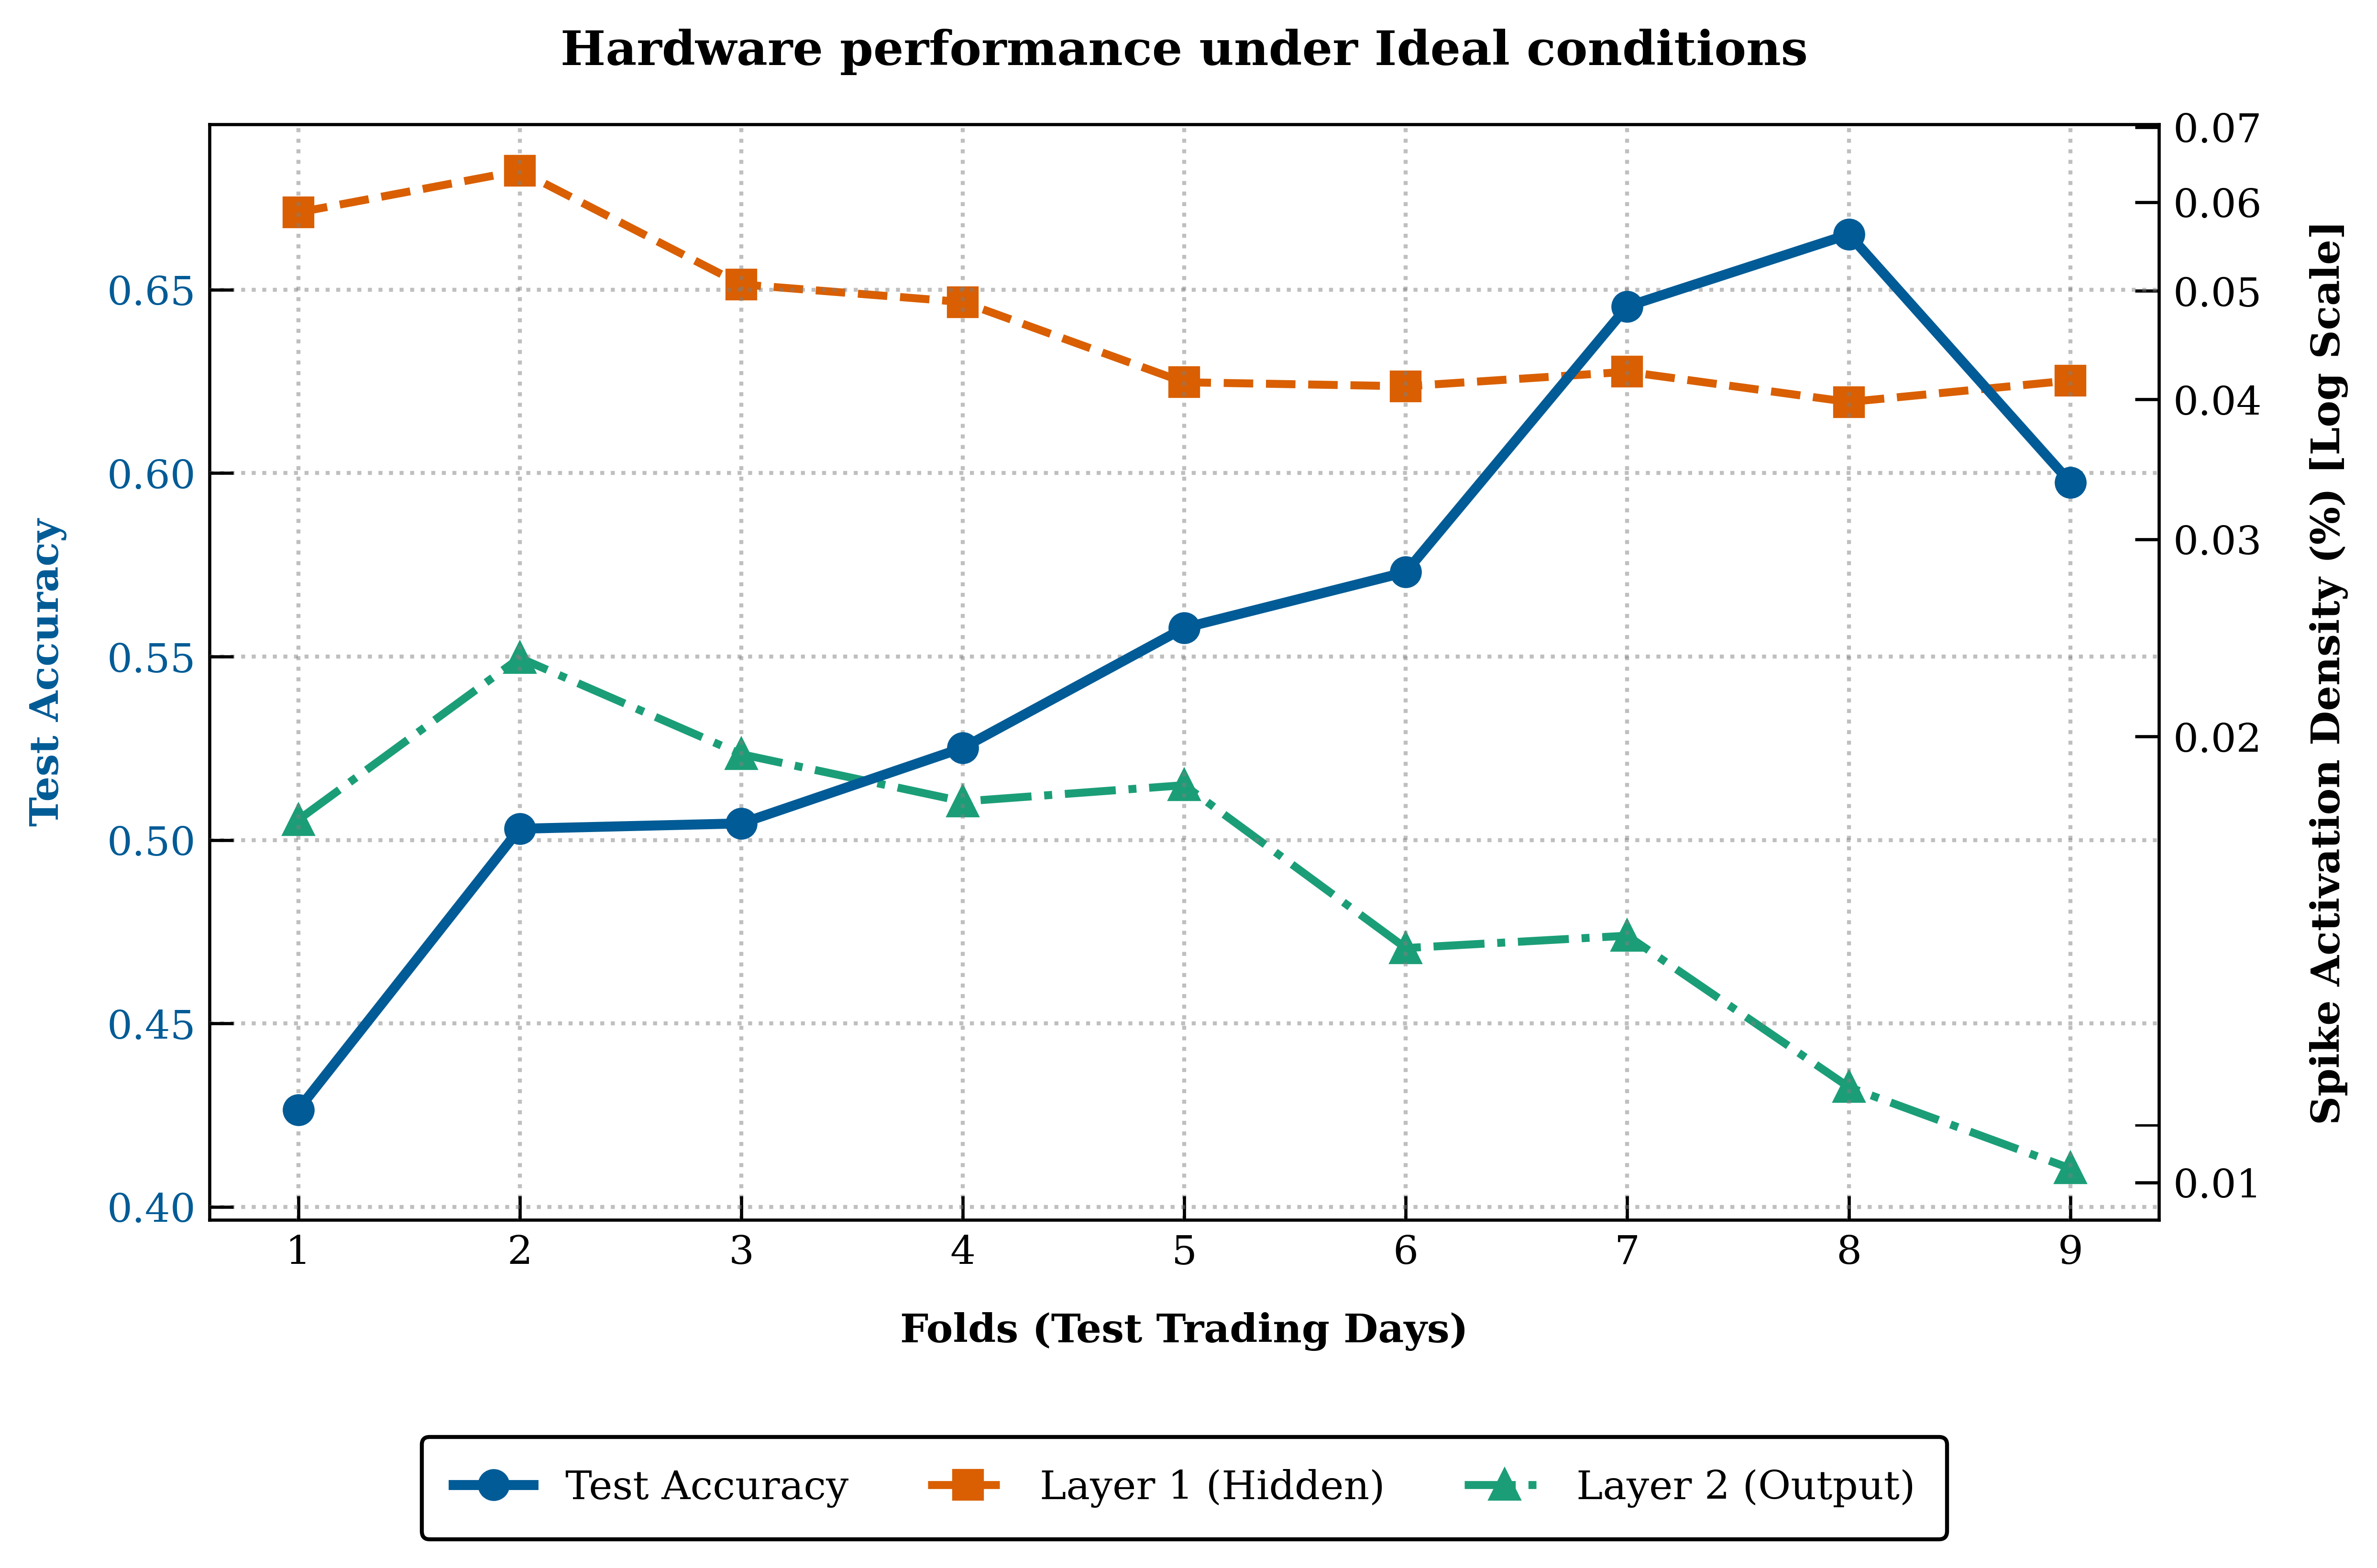

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

folds = np.arange(1, 10)
test_accuracy_ideal = np.array([item["accuracy"] for item in fold_summary_metrics_ideal])
l1_density_ideal = np.array([item["l1_sparsity"] for item in fold_summary_metrics_ideal])
l2_density_ideal = np.array([item["l2_sparsity"] for item in fold_summary_metrics_ideal])

# matplotlib params
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"]  = ["Times New Roman", "DejaVu Serif", "Computer Modern Roman"]

fig, ax1 = plt.subplots(figsize=(8.5, 5.8), dpi=600) 

ax1.set_xlabel('Folds (Test Trading Days)', fontweight='bold', labelpad=10)
ax1.set_ylabel('Test Accuracy', color="#005b96", fontweight='bold', labelpad=10)
line1 = ax1.plot(folds, test_accuracy_ideal, color="#005b96", marker='o', linewidth=2.5, markersize=7, label='Test Accuracy')

ymin = min(test_accuracy_ideal) - 0.03
ymax = max(test_accuracy_ideal) + 0.03
ax1.set_ylim(min(0.40, ymin), max(0.65, ymax)) 

ax1.tick_params(axis='y', labelcolor="#005b96", length=6)
ax1.tick_params(axis='x', length=6)
ax1.set_xticks(folds) 

ax1.grid(True, linestyle=':', color='gray', alpha=0.5, linewidth=1.0)

ax2 = ax1.twinx()
ax2.set_ylabel('Spike Activation Density (%) [Log Scale]', color='black', fontweight='bold', labelpad=12)

line2 = ax2.plot(folds, l1_density_ideal, color="#d95f02", marker='s', linestyle='--', linewidth=2, markersize=7, label='Layer 1 (Hidden)')
line3 = ax2.plot(folds, l2_density_ideal, color="#1b9e77", marker='^', linestyle='-.', linewidth=2, markersize=7, label='Layer 2 (Output)')
ax2.set_yscale('log')

all_densities = np.concatenate([l1_density_ideal, l2_density_ideal])
ax2.set_ylim(min(all_densities) * 0.9, max(all_densities) * 1.1)
ax2.yaxis.set_major_locator(ticker.LogLocator(base=10.0, subs=(0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8)))

ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
ax2.yaxis.set_minor_formatter(ticker.NullFormatter()) 

ax2.tick_params(axis='y', which='both', labelcolor='black', length=6, direction='in')

ax1.set_zorder(ax2.get_zorder() + 1)  
ax1.set_frame_on(False)               
ax2.set_frame_on(True)                

lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, 
           frameon=True, facecolor='white', edgecolor='black', framealpha=1.0, borderpad=0.8)

plt.title("Hardware performance under Ideal conditions", fontweight='bold', pad=15)

fig.tight_layout(pad=1.5)
plt.savefig("evaluation_plot_ideal.pdf", format='pdf', bbox_inches='tight')
plt.show()


In [ ]:
print(fold_summary_metrics_ideal)
print(l1_density_ideal)
print(l2_density_ideal)
print(l1_density_ideal.min(), l1_density_ideal.max())
print(l2_density_ideal.min(), l2_density_ideal.max())

[{'fold': 1, 'accuracy': 0.426505082095387, 'l1_sparsity': 0.05873994168621319, 'l2_sparsity': 0.01685344453131787, 'input_sparsity': 0.08046234510838986}, {'fold': 2, 'accuracy': 0.503069636905806, 'l1_sparsity': 0.06399758996959598, 'l2_sparsity': 0.02351439318638056, 'input_sparsity': 0.07004034762149272}, {'fold': 3, 'accuracy': 0.5045276388701175, 'l1_sparsity': 0.050660527041942606, 'l2_sparsity': 0.01928939346157889, 'input_sparsity': 0.07360927978980131}, {'fold': 4, 'accuracy': 0.5251043015393468, 'l1_sparsity': 0.048858565014626196, 'l2_sparsity': 0.017505075209002702, 'input_sparsity': 0.07766987356756415}, {'fold': 5, 'accuracy': 0.5578274760383387, 'l1_sparsity': 0.04143091054313099, 'l2_sparsity': 0.018100106496272632, 'input_sparsity': 0.07111013476406375}, {'fold': 6, 'accuracy': 0.5730171489817792, 'l1_sparsity': 0.0410950339406931, 'l2_sparsity': 0.012951053947838513, 'input_sparsity': 0.07015163116157055}, {'fold': 7, 'accuracy': 0.6454463480613165, 'l1_sparsity': 0.

In [ ]:
print(folds)

[1 2 3 4 5 6 7 8 9]


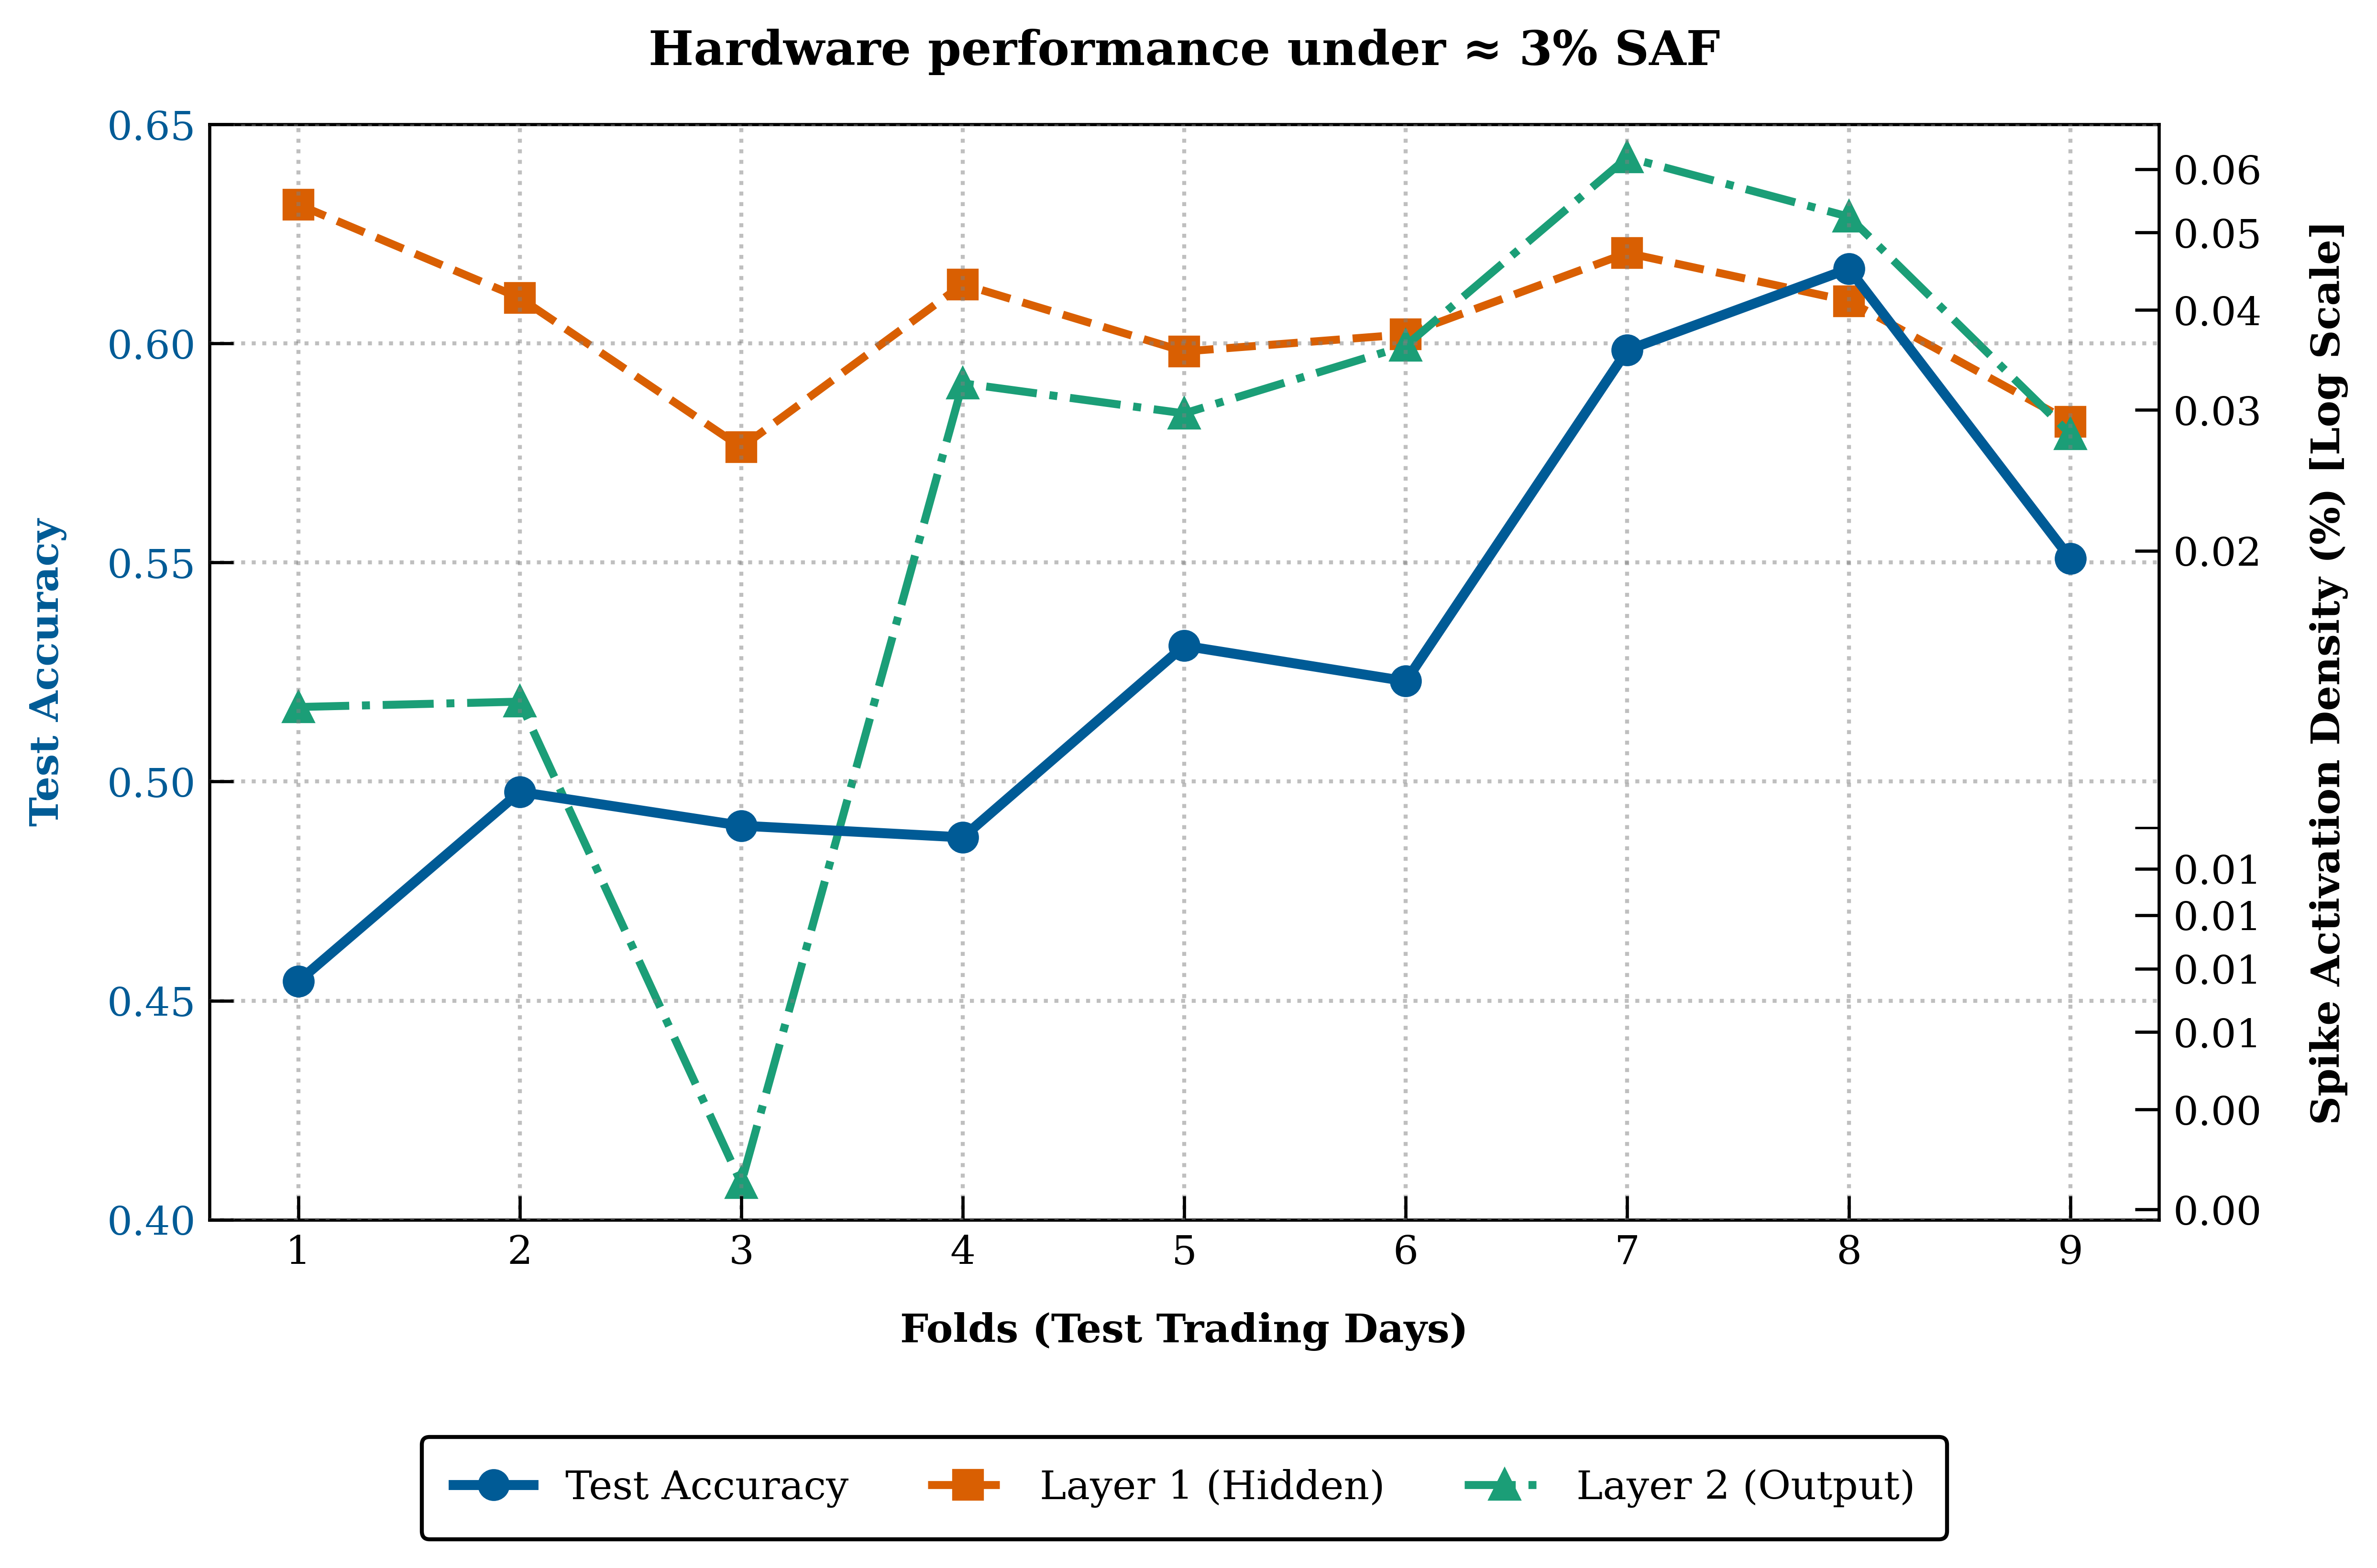

In [11]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# Sample arrays matching your code structure
folds = np.arange(1, 10)

accuracy = np.array([item["accuracy"] for item in fold_summary_metrics])
l1_density = np.array([item["l1_sparsity"] for item in fold_summary_metrics])
l2_density = np.array([item["l2_sparsity"] for item in fold_summary_metrics])

# Globally force classic MATLAB inward ticks and formatting
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"]  = ["Times New Roman", "DejaVu Serif", "Computer Modern Roman"]

# Adjusted figure size slightly to make clean room for the bottom legend
fig, ax1 = plt.subplots(figsize=(8.5, 5.8), dpi=600) 

# Configure Primary Axis (Left)
ax1.set_xlabel('Folds (Test Trading Days)', fontweight='bold', labelpad=10)
ax1.set_ylabel('Test Accuracy', color="#005b96", fontweight='bold', labelpad=10)
line1 = ax1.plot(folds, accuracy, color="#005b96", marker='o', linewidth=2.5, markersize=7, label='Test Accuracy')

# --- FIX 1: Dynamic vertical bounds to prevent lines cutting through the top frame ---
ymin = min(accuracy) - 0.03
ymax = max(accuracy) + 0.03
ax1.set_ylim(min(0.40, ymin), max(0.65, ymax)) 

ax1.tick_params(axis='y', labelcolor="#005b96", length=6)
ax1.tick_params(axis='x', length=6)
ax1.set_xticks(folds) # Explicitly show every fold integer

# MATLAB-style grid layout
ax1.grid(True, linestyle=':', color='gray', alpha=0.5, linewidth=1.0)

# Configure Secondary Axis (Right)
ax2 = ax1.twinx()
ax2.set_ylabel('Spike Activation Density (%) [Log Scale]', color='black', fontweight='bold', labelpad=12)

line2 = ax2.plot(folds, l1_density, color="#d95f02", marker='s', linestyle='--', linewidth=2, markersize=7, label='Layer 1 (Hidden)')
line3 = ax2.plot(folds, l2_density, color="#1b9e77", marker='^', linestyle='-.', linewidth=2, markersize=7, label='Layer 2 (Output)')

# Apply log scale
ax2.set_yscale('log')

# --- FIX 2: Set precise data limits and force log sub-interval ticks to display values ---
all_densities = np.concatenate([l1_density, l2_density])
ax2.set_ylim(min(all_densities) * 0.9, max(all_densities) * 1.1)

# Places ticks at fractional intervals within a single decade to guarantee visibility
ax2.yaxis.set_major_locator(ticker.LogLocator(base=10.0, subs=(0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8)))

# Clean MATLAB scalar format (e.g., 0.25 instead of 2.5 x 10^-1)
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
ax2.yaxis.set_minor_formatter(ticker.NullFormatter()) 

# Apply tick styling to major and minor ticks on the right axis border
ax2.tick_params(axis='y', which='both', labelcolor='black', length=6, direction='in')

# Fix the broken top bounding box line caused by twinx
ax1.set_zorder(ax2.get_zorder() + 1)  
ax1.set_frame_on(False)               
ax2.set_frame_on(True)                

# Unified Legend - Positioned safely OUTSIDE below the X-axis
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]

# bbox_to_anchor points to (X, Y) coordinates relative to axes. (0.5, -0.18) drops it right below the center point.
ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, 
           frameon=True, facecolor='white', edgecolor='black', framealpha=1.0, borderpad=0.8)

# Title for the SAF dataset
plt.title("Hardware performance under ≈ 3% SAF", fontweight='bold', pad=15)

# Use tight_layout with specified padding to ensure everything fits inside the PDF boundary
fig.tight_layout(pad=1.5)

# bbox_inches='tight' is critical here to ensure the outside legend isn't cropped during export
plt.savefig("evaluation_plot.pdf", format='pdf', bbox_inches='tight')
plt.show()


In [ ]:
print(fold_summary_metrics[-1])

{'fold': 9, 'accuracy': 0.5454403008461297, 'l1_sparsity': 0.0213890956335527, 'l2_sparsity': 0.01590932831923117, 'input_sparsity': 0.061916509568691255}


In [ ]:
# LSTM network to benchmark against our Memristive spiking neural network
class LSTM_net(nn.Module): 
    def __init__(self, input_size=288, hidden_size=128, num_classes=3):
        super(LSTM_net, self).__init__()
        
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, batch_first=True) 
        self.drop = nn.Dropout(.3)
        self.fc = nn.Linear(hidden_size, num_classes)
        
    def forward(self, x):
        out, _ = self.lstm(x)
        
        final_step_out = out[:, -1, :]
        final_step_out = self.drop(final_step_out)
        logits = self.fc(final_step_out)
        
        return logits
    
print(f"starting LSTM training on {device}")
torch.manual_seed(123)
lstm_fold_summary = []

lstm_net = LSTM_net(input_size=288, hidden_size=128, num_classes=3).to(device)

for fold_idx in range(9):
    print("*"*50 +  f"\n LSTM fold n° {fold_idx + 1}")
    
    train_loader, test_loader, fold_train_dataset = get_anchored_fold_loaders(
        fold_idx=fold_idx, 
        train_files=train_files, 
        test_files=test_files, 
        batch_size=256
    )
    
    if isinstance(fold_train_dataset, torch.utils.data.ConcatDataset):
        active_labels = torch.cat([ds.Y for ds in fold_train_dataset.datasets])
    else:
        active_labels = fold_train_dataset.Y
        
    if isinstance(fold_train_dataset, torch.utils.data.ConcatDataset):
        active_labels = torch.cat([ds.Y for ds in fold_train_dataset.datasets])
    else:
        active_labels = fold_train_dataset.Y
        
    w = weights(device=device, labels=active_labels)
    loss_fn = FocalLoss(alpha=w, gamma=2)
    
    num_epochs_per_fold = 10  
    optimizer = torch.optim.Adam(lstm_net.parameters(), lr=3e-4, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs_per_fold, eta_min=1e-6)
    
    best_fold_acc = 0.0
    patience_counter = 0
    patience = 4
    
    for epoch in range(num_epochs_per_fold):
        lstm_net.train()
        epoch_loss = 0.0
        
        for batch_idx, (data, targets) in enumerate(train_loader):
            data = data.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True).long()
            
            optimizer.zero_grad(set_to_none=True)
            logits = lstm_net(data)
            loss_val = loss_fn(logits, targets)
            
            loss_val.backward()
            torch.nn.utils.clip_grad_norm_(lstm_net.parameters(), max_norm=1.0)
            optimizer.step()
            
            epoch_loss += loss_val.item()
            
        scheduler.step()
        avg_loss = epoch_loss / len(train_loader)
        
        # Evaluate 
        lstm_net.eval()
        with torch.no_grad():
            val_correct = 0
            val_total = 0
            for val_data, val_targets in test_loader:
                val_data = val_data.to(device, non_blocking=True)
                val_targets = val_targets.to(device, non_blocking=True).long()
                val_preds = lstm_net(val_data).argmax(dim=1)
                val_correct += (val_preds == val_targets).sum().item()
                val_total += val_targets.size(0)
            current_val_acc = val_correct / max(1, val_total)
            
        print(f"Fold {fold_idx+1} | Epoch [{epoch+1}/{num_epochs_per_fold}] | Loss: {avg_loss:.4f} | LSTM Test Acc: {current_val_acc*100:.2f}%")
        
        if current_val_acc > best_fold_acc:
            best_fold_acc = current_val_acc
            patience_counter = 0
            torch.save(lstm_net.state_dict(), f'best_lstm_fold_{fold_idx+1}.pt')
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("Early stopping LSTM fold fine-tuning.")
                break

    print(f"\n--- Saving LSTM Metrics for Fold {fold_idx + 1} ---")
    lstm_fold_summary.append({
        "fold": fold_idx + 1,
        "accuracy": best_fold_acc
    })

print("\n" + "="*50)
print("FINAL LSTM BASELINE REPORT")
print("="*50)
print(f"{'Fold':<6} | {'LSTM Test Accuracy':<20}")
print("-"*50)
lstm_total_acc = 0
for entry in lstm_fold_summary:
    print(f"{entry['fold']:<6} | {entry['accuracy']*100:<19.2f}%")
    lstm_total_acc += entry['accuracy']

print("="*50)
print(f"LSTM 8-Fold Average Accuracy: {(lstm_total_acc / 8)*100:.2f}%")
    

starting LSTM training on cuda
**************************************************
 LSTM fold n° 1

 ***** fold 1 / 9 training on:Train_Dst_NoAuction_MinMax_CF_1.txt and testing on:Test_Dst_NoAuction_MinMax_CF_1.txt
tensor([0.9808, 0.6656, 1.0776])
Fold 1 | Epoch [1/10] | Loss: 0.3602 | LSTM Test Acc: 32.41%
Fold 1 | Epoch [2/10] | Loss: 0.3394 | LSTM Test Acc: 42.83%
Fold 1 | Epoch [3/10] | Loss: 0.3238 | LSTM Test Acc: 56.15%
Fold 1 | Epoch [4/10] | Loss: 0.3070 | LSTM Test Acc: 59.07%
Fold 1 | Epoch [5/10] | Loss: 0.2915 | LSTM Test Acc: 59.23%
Fold 1 | Epoch [6/10] | Loss: 0.2788 | LSTM Test Acc: 59.08%
Fold 1 | Epoch [7/10] | Loss: 0.2699 | LSTM Test Acc: 59.11%
Fold 1 | Epoch [8/10] | Loss: 0.2651 | LSTM Test Acc: 58.72%
Fold 1 | Epoch [9/10] | Loss: 0.2618 | LSTM Test Acc: 58.84%
↳ Early stopping LSTM fold fine-tuning.

--- Saving LSTM Metrics for Fold 1 ---
**************************************************
 LSTM fold n° 2

 ***** fold 2 / 9 training on:Train_Dst_NoAuction_MinMa

In [ ]:
def calculate_hardware_metrics(input_density=0.02, l1_density=0.0188, l2_density=0.0055, log=True):
    inputs = 288
    hidden = 128
    outputs = 3
    timesteps = 30

    # --- Corrected Hardware Parameters ---
    bits_per_device = 4
    devices_per_weight = 2  
    
    # Adjusted upward to account for parasitic line capacitance (RC delay)
    energy_per_synop_pj = 1.0       
    
    # Adjusted to reflect full column readout overhead (not just an isolated SAR step)
    adc_energy_pj_per_read = 8.0    
    
    # Added: Energy consumed by LIF neuron membrane integration per timestep
    energy_per_neuron_step_pj = 2.5 
    
    # Adjusted upward to reflect real peripheral control circuits + distribution networks
    static_power_uw = 75.0            
    latency_per_step_ns = 100

    # Topology and memory
    params_l1 = inputs * hidden
    params_l2 = hidden * outputs
    total_params = params_l1 + params_l2
    total_devices = total_params * devices_per_weight
    memory_footprint_kb = (total_devices * bits_per_device) / (8 * 1024)

    # Spike and SynOp math
    total_input_spikes = inputs * timesteps * input_density
    total_hidden_spikes = hidden * timesteps * l1_density
    synops_l1 = total_input_spikes * hidden
    synops_l2 = total_hidden_spikes * outputs
    total_synops = synops_l1 + synops_l2

    # --- Energy Components (Calculated in nJ) ---
    synop_energy_nj = (total_synops * energy_per_synop_pj) / 1000  
    
    total_adc_reads = (hidden + outputs) * timesteps
    adc_energy_nj = (total_adc_reads * adc_energy_pj_per_read) / 1000  

    # Added: Neuron integration energy component
    total_neuron_updates = (hidden + outputs) * timesteps
    neuron_energy_nj = (total_neuron_updates * energy_per_neuron_step_pj) / 1000

    latency_us = (timesteps * latency_per_step_ns) / 1000
    static_energy_nj = (static_power_uw * latency_us) / 1000  

    # Updated system energy sum
    total_energy_nj = synop_energy_nj + adc_energy_nj + neuron_energy_nj + static_energy_nj

    # ... keeping your logging format below ...

    metrics = []
    if log:
        print("*"*50)
        print("hardware metrics:")
        print("*"*50)
        print(f"Number of parameters:       {total_params:,}")
        print(f"Number of RRAM Devices:     {total_devices:,} (Differential)")
        print(f"Memory Footprint:           {memory_footprint_kb:.2f} KB")
        print("+" * 50)
        print(f"Average L1 Firing Rate:     {l1_density * 100:.2f}%")
        print(f"Average L2 Firing Rate:     {l2_density * 100:.2f}%")
        print(f"Total Input Spikes:         {int(total_input_spikes):,}")
        print(f"Total Hidden Spikes:        {int(total_hidden_spikes):,}")
        print("+" * 50)
        print(f"Total SynOps:               {int(total_synops):,}")
        print(f"  -> Device-level SynOp Energy:  {synop_energy_nj:.4f} nJ  (analog crossbar switching only)")
        print(f"  -> ADC Conversion Energy:      {adc_energy_nj:.4f} nJ  ({total_adc_reads} reads @ {adc_energy_pj_per_read} pJ/read)")
        print(f"  -> Static/Leakage Energy:      {static_energy_nj:.4f} nJ  (@ {static_power_uw} µW over {latency_us:.2f} µs)")
        print(f"  -> TOTAL System-Level Energy:  {total_energy_nj:.4f} nJ")
        print(f"Inference Latency:          {latency_us:.2f} µs")
        print("+"*50)
        print("NOTE: Device-level SynOp energy alone is NOT directly comparable to full-chip")
        print("      measurements (e.g. Wu et al. 2021, 10.3 µJ/sample) which include ADC,")
        print("      periphery, and static power over a much longer real sample duration.")
        print("+"*50)

    metrics.append({
        "num_param": total_params,
        "num_rram": total_devices,
        "memory": memory_footprint_kb,
        "total_hidden_spikes": int(total_hidden_spikes),
        "total_input_spikes": int(total_input_spikes),
        "total_synops": int(total_synops),
        "synop_energy_nj": synop_energy_nj,
        "adc_energy_nj": adc_energy_nj,
        "static_energy_nj": static_energy_nj,
        "total_energy_nj": total_energy_nj,
        "inference_latency": latency_us,
    })

    return metrics

avg_l1_density = np.mean([item["l1_sparsity"] for item in fold_summary_metrics])
avg_l2_density = np.mean([item["l2_sparsity"] for item in fold_summary_metrics])
avg_input_density = np.mean([item["input_sparsity"] for item in fold_summary_metrics])

ms = calculate_hardware_metrics(input_density=avg_input_density, l1_density=avg_l1_density, l2_density=avg_l2_density)
print(avg_input_density)

# **************************************************
# hardware metrics:
# **************************************************
# Number of parameters:       37,248
# Number of RRAM Devices:     74,496 (Differential)
# Memory Footprint:           36.38 KB
# ++++++++++++++++++++++++++++++++++++++++++++++++++
# Average L1 Firing Rate:     2.97%
# Average L2 Firing Rate:     2.50%
# Total Input Spikes:         589
# Total Hidden Spikes:        114
# ++++++++++++++++++++++++++++++++++++++++++++++++++
# Total SynOps:               75,734
#   -> Device-level SynOp Energy:  75.7349 nJ  (analog crossbar switching only)
#   -> ADC Conversion Energy:      31.4400 nJ  (3930 reads @ 8.0 pJ/read)
#   -> Static/Leakage Energy:      0.2250 nJ  (@ 75.0 µW over 3.00 µs)
#   -> TOTAL System-Level Energy:  117.2249 nJ
# Inference Latency:          3.00 µs
# ++++++++++++++++++++++++++++++++++++++++++++++++++
# NOTE: Device-level SynOp energy alone is NOT directly comparable to full-chip
#       measurements (e.g. Wu et al. 2021, 10.3 µJ/sample) which include ADC,
#       periphery, and static power over a much longer real sample duration.
# ++++++++++++++++++++++++++++++++++++++++++++++++++
# 0.06817163797457093

**************************************************
hardware metrics:
**************************************************
Number of parameters:       37,248
Number of RRAM Devices:     74,496 (Differential)
Memory Footprint:           36.38 KB
++++++++++++++++++++++++++++++++++++++++++++++++++
Average L1 Firing Rate:     3.17%
Average L2 Firing Rate:     1.62%
Total Input Spikes:         600
Total Hidden Spikes:        121
++++++++++++++++++++++++++++++++++++++++++++++++++
Total SynOps:               77,267
  -> Device-level SynOp Energy:  77.2679 nJ  (analog crossbar switching only)
  -> ADC Conversion Energy:      31.4400 nJ  (3930 reads @ 8.0 pJ/read)
  -> Static/Leakage Energy:      0.2250 nJ  (@ 75.0 µW over 3.00 µs)
  -> TOTAL System-Level Energy:  118.7579 nJ
Inference Latency:          3.00 µs
++++++++++++++++++++++++++++++++++++++++++++++++++
NOTE: Device-level SynOp energy alone is NOT directly comparable to full-chip
      measurements (e.g. Wu et al. 2021, 10.3 µJ/sample) whi

In [ ]:
!ls

best_lstm_fold_1.pt  best_lstm_fold_6.pt  evaluation_plot_ideal.pdf
best_lstm_fold_2.pt  best_lstm_fold_7.pt  evaluation_plot.pdf
best_lstm_fold_3.pt  best_lstm_fold_8.pt  sample_data
best_lstm_fold_4.pt  best_lstm_fold_9.pt
best_lstm_fold_5.pt  drive


In [ ]:
# ======================================================================
# Digital LSTM vs. MSNN Hardware & Area Comparison Calculator
# ======================================================================

def calculate_baseline_comparison():
    # --- 1. Architectural & Topography Constants ---
    inputs = 288
    hidden = 128
    outputs = 3
    timesteps = 30
    
    # MSNN values from your hardware profile
    msnn_devices = ms[0]["num_rram"]
    msnn_synops = ms[0]["total_synops"]
    msnn_energy_nj = ms[0]["total_energy_nj"]
    
    # --- 2. LSTM Calculations ---
    # LSTM has 4 gates: Input, Forget, Cell, Output
    # Parameters per gate = (Inputs * Hidden) + (Hidden * Hidden) + Hidden (bias)
    params_per_gate = (inputs * hidden) + (hidden * hidden) + hidden
    lstm_params_layer = 4 * params_per_gate
    lstm_params_output = (hidden * outputs) + outputs
    lstm_total_params = lstm_params_layer + lstm_params_output
    
    # Dense LSTMs perform MAC operations for every parameter at every timestep
    lstm_total_macs = lstm_total_params * timesteps
    
    # Energy constant for 32-bit floating-point digital MAC (Horowitz ISSCC standard: ~3.1 pJ per MAC)
    energy_per_mac_pj = 3.1
    lstm_energy_nj = (lstm_total_macs * energy_per_mac_pj) / 1000
    
    # --- 3. Area Estimation Constants (RRAM CIM vs. Digital CMOS) ---
    # Approximate layout area per RRAM device (assuming standard crossbar node, e.g., 65nm or 28nm roughly ~4-10 F^2)
    # Let's use a standard literature estimate: ~0.04 um^2 per RRAM cell including minimal peripheral CMOS footprint share
    # Or macro-level density estimation: ~1000 um^2 per Kb for dense RRAM crossbars.
    rram_area_per_device_um2 = 0.04 
    msnn_crossbar_area_um2 = msnn_devices * rram_area_per_device_um2
    
    # Digital Standard Cell Area estimation for LSTM (32-bit floating point MAC units and registers)
    # A standard 32-bit FP MAC cell in CMOS takes roughly 10,000 to 20,000 gates (~5000 um^2 at 65nm per equivalent gate block)
    # Alternatively, total area proportional to parameter storage and active datapath logic.
    # Let's provide a clear transistor/gate equivalent layout approximation.
    digital_gate_area_um2 = 1.5  # Typical 65nm 2-input NAND equivalent area
    # A 32-bit floating point multiplier/accumulator takes roughly 15,000 equivalent gates. 
    # For a dense sequential LSTM running parallel blocks, let's derive footprint via standard synthesized cell area:
    lstm_estimated_area_um2 = lstm_total_params * 32 * digital_gate_area_um2 * 0.5 # compressed footprint factor

    # --- 4. Print Comparison Table ---
    print("="*65)
    print(f"{'HARDWARE METRIC':<30} | {'MSNN (RRAM CIM)':<15} | {'Digital LSTM':<15}")
    print("="*65)
    print(f"{'Parameters':<30} | {37248:<15,} | {lstm_total_params:<15,}")
    print(f"{'Memory Elements / Devices':<30} | {msnn_devices:<15,} | {lstm_total_params * 32:<15,}")
    print(f"{'Operations (SynOps vs MACs)':<30} | {msnn_synops:<15,} | {lstm_total_macs:<15,}")
    print(f"{'Estimated Energy (nJ)':<30} | {msnn_energy_nj:<15.4f} | {lstm_energy_nj:<15.2f}")
    print(f"{'Approx. Silicon Area (um²)':<30} | {msnn_crossbar_area_um2:<15.2f} | {lstm_estimated_area_um2:<15.2f}")
    print("="*65)
    
    # Efficiency Multipliers
    energy_speedup = lstm_energy_nj / msnn_energy_nj
    op_reduction = lstm_total_macs / msnn_synops
    print(f"\n[SUMMARY] MSNN achieves a {op_reduction:.1f}x reduction in operations")
    print(f"[SUMMARY] MSNN achieves a {energy_speedup:.1f}x improvement in energy efficiency over the LSTM baseline.")

calculate_baseline_comparison()

HARDWARE METRIC                | MSNN (RRAM CIM) | Digital LSTM   
Parameters                     | 37,248          | 213,891        
Memory Elements / Devices      | 74,496          | 6,844,512      
Operations (SynOps vs MACs)    | 77,267          | 6,416,730      
Estimated Energy (nJ)          | 118.7579        | 19891.86       
Approx. Silicon Area (um²)     | 2979.84         | 5133384.00     

[SUMMARY] MSNN achieves a 83.0x reduction in operations
[SUMMARY] MSNN achieves a 167.5x improvement in energy efficiency over the LSTM baseline.


In [ ]:
# import torch
# import glob
# import numpy as np
# # (Include your other original imports here)

# # 1. PASTE YOUR CLASSES AND FUNCTIONS HERE
# # Paste: STEQuantize, MemristorCrossbar, MSNN, LOBDayDataset
# # Paste: get_anchored_fold_loaders

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # 2. DEFINE YOUR DATA FILES (Update these paths for your new environment)
# train_files = sorted(glob.glob(
#     "./drive/MyDrive/data/published/BenchmarkDatasets/BenchmarkDatasets/BenchmarkDatasets/NoAuction/NoAuction_MinMax/NoAuction_MinMax_Training/Train_Dst_NoAuction_MinMax_CF_*.txt"
# ))
# test_files = sorted(glob.glob(
#     "./drive/MyDrive/data/published/BenchmarkDatasets/BenchmarkDatasets/BenchmarkDatasets/NoAuction/NoAuction_MinMax/NoAuction_MinMax_Testing/Test_Dst_NoAuction_MinMax_CF_*.txt"
# ))

# for i in range(9):
#     # 3. SELECT THE FOLD YOU WANT TO TEST
#     fold_idx = i # fold_idx = 0 means Fold 1
#     print(fold_idx)
#     # 4. LOAD THE ANCHORED DATA FOR THIS SPECIFIC FOLD
#     # We only need the test_loader for inference, so we can ignore the train returns
#     _, test_loader, _ = get_anchored_fold_loaders(
#         fold_idx=fold_idx, 
#         train_files=train_files, 
#         test_files=test_files, 
#         batch_size=256
#     )

#     # 5. INSTANTIATE THE MODEL
#     new = MSNN(
#         num_inputs=288, 
#         num_hidden=128, 
#         num_outputs=3, 
#         beta=0.9, 
#         num_levels=16, 
#         saf_rate=0.03, 
#         noise_std=0.05,
#         force_ideal=False,
#         force_noise_eval=True
#     ).to(device)

#     # 6. LOAD THE CORRESPONDING WEIGHTS
#     # Match the model number to the fold_idx (fold_idx 0 -> model_1.pt)
#     checkpoint_path = f'/kaggle/working/MSNN/noisy/model_8.pt'
#     new.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))

#     new.eval()
#     new.reset_spike_metrics()

#     # 7. RUN INFERENCE
#     correct = 0
#     total = 0

#     print(f"\nRunning inference on Fold {fold_idx + 1}...")
#     with torch.no_grad():
#         for data, targets in test_loader:
#             data = data.to(device, non_blocking=True)
#             targets = targets.to(device, non_blocking=True).long()
            
#             logits = new(data)
#             preds = logits.argmax(dim=1)
            
#             correct += (preds == targets).sum().item()
#             total += targets.size(0)

#     accuracy = correct / max(1, total)
#     print(accuracy)
#     print(f"Test Accuracy for Fold {fold_idx + 1}: {accuracy * 100:.2f}%")

    


0

 ***** fold 1 / 9 training on:Train_Dst_NoAuction_MinMax_CF_1.txt and testing on:Test_Dst_NoAuction_MinMax_CF_1.txt
params memristor: 16, 0.03, 0.05, 0.05, 0.002
params memristor: 16, 0.03, 0.05, 0.05, 0.002


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/MSNN/noisy/model_8.pt'

In [ ]:
# this code section does the following experiment
# it runs both MSNN ideal and noisy on different seeds (42, 7, 3)
# the metrics are saved for to decide which seed is better for training 

def run_anchored_experiment(seed, force_ideal, force_noise_eval, train_files, test_files,
                             num_folds=9, num_epochs_per_fold=10, patience=4,
                             checkpoint_dir='./drive/MyDrive/data/sweep'):
    """
    Runs the full anchored-fold training+eval pipeline once, for one seed and one
    hardware condition. Returns a list of per-fold metric dicts (same shape as
    your existing fold_summary_metrics).
    """
    os.makedirs(checkpoint_dir, exist_ok=True)
   
    fold_summary = []

    for fold_idx in range(num_folds):
        train_loader, test_loader, fold_train_dataset = get_anchored_fold_loaders(
            fold_idx=fold_idx, 
            train_files=train_files,
            test_files=test_files,
            batch_size=256
        )
        torch.manual_seed(seed)
        
        net_seeds = MSNN(num_inputs=288,
                       num_hidden=128,
                       num_outputs=3,
                       beta=0.9,
                       num_levels=16,
                       saf_rate=0.03,
                       noise_std=0.05,
                       force_ideal=force_ideal,
                       force_noise_eval=force_noise_eval
                       ).to(device)
            
        if isinstance(fold_train_dataset, torch.utils.data.ConcatDataset):
            active_labels = torch.cat([ds.Y for ds in fold_train_dataset.datasets])
        else:
            active_labels = fold_train_dataset.Y

        w = weights(device=device, labels=active_labels)
        loss_fn = FocalLoss(alpha=w, gamma=2)

        optimizer = torch.optim.Adam(net_seeds.parameters(), lr=3e-4, weight_decay=1e-5)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs_per_fold, eta_min=1e-6)

        best_fold_acc = 0.0
        patience_counter = 0
        ckpt_path = f'{checkpoint_dir}/seed{seed}_{"ideal" if force_ideal else "noisy"}_fold{fold_idx+1}.pt'

        for epoch in range(num_epochs_per_fold):
            net_seeds.train()
            
            for data, targets in train_loader:
                data = data.to(device, non_blocking=True)
                targets = targets.to(device, non_blocking=True).long()
                
                optimizer.zero_grad(set_to_none=True)
                
                loss_val = loss_fn(net_seeds(data), targets)
                
                loss_val.backward()
                torch.nn.utils.clip_grad_norm_(net_seeds.parameters(), max_norm=1.0)
                optimizer.step()
            scheduler.step()

            net_seeds.eval()
            with torch.no_grad():
                correct, total = 0, 0
                for val_data, val_targets in test_loader:
                    val_data = val_data.to(device, non_blocking=True)
                    val_targets = val_targets.to(device, non_blocking=True).long()
                    preds = net_seeds(val_data).argmax(dim=1)
                    correct += (preds == val_targets).sum().item()
                    total += val_targets.size(0)
                current_val_acc = correct / max(1, total)

            if current_val_acc > best_fold_acc:
                best_fold_acc = current_val_acc
                patience_counter = 0
                torch.save(net_seeds.state_dict(), ckpt_path)
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    break

        net_seeds.load_state_dict(torch.load(ckpt_path, map_location=device))

        total_input_sparsity, num_batches = 0.0, 0
        with torch.no_grad():
            for val_data, _ in test_loader:
                total_input_sparsity += val_data.float().mean().item()
                num_batches += 1
        fold_input_sparsity = total_input_sparsity / num_batches

        fold_profile = compute_hardware_metrics(test_loader, net_seeds, device)
        fold_summary.append({
            "fold": fold_idx + 1,
            "accuracy": fold_profile["accuracy"],
            "l1_sparsity": fold_profile["l1_sparsity"],
            "l2_sparsity": fold_profile["l2_sparsity"],
            "input_sparsity": fold_input_sparsity
        })

    return fold_summary


# Run Sweeeep
seeds = [42, 7, 3]   
all_noisy_runs = [fold_summary_metrics]
all_ideal_runs = []

for s in seeds:
    print(f"\n===== SEED {s} — NOISY =====")
    all_noisy_runs.append(run_anchored_experiment(s, force_ideal=False, force_noise_eval=True,
                                                    train_files=train_files, test_files=test_files))
    print(f"\n===== SEED {s} — IDEAL =====")
    all_ideal_runs.append(run_anchored_experiment(s, force_ideal=True, force_noise_eval=False,
                                                    train_files=train_files, test_files=test_files))


===== SEED 42 — NOISY =====
params memristor: 16, 0.03, 0.05, 0.05, 0.002
params memristor: 16, 0.03, 0.05, 0.05, 0.002

 ***** fold 1 / 9 training on:Train_Dst_NoAuction_MinMax_CF_1.txt and testing on:Test_Dst_NoAuction_MinMax_CF_1.txt
tensor([0.9808, 0.6656, 1.0776])

*** extracted hardware metrics ***
accuracy: 41.59%
layer 1 firing density : 4.238% spikes/neuron/step
layer 2 firing density : 0.064% spikes/neuron/step
total spikes emitted per sequence window (30): 162.81

 ***** fold 2 / 9 training on:Train_Dst_NoAuction_MinMax_CF_2.txt and testing on:Test_Dst_NoAuction_MinMax_CF_2.txt
tensor([0.9550, 0.7054, 1.0151])

*** extracted hardware metrics ***
accuracy: 45.04%
layer 1 firing density : 2.631% spikes/neuron/step
layer 2 firing density : 0.069% spikes/neuron/step
total spikes emitted per sequence window (30): 101.08

 ***** fold 3 / 9 training on:Train_Dst_NoAuction_MinMax_CF_3.txt and testing on:Test_Dst_NoAuction_MinMax_CF_3.txt
tensor([0.9857, 0.6828, 1.0299])

*** extrac

In [ ]:
def aggregate_across_seeds(all_runs, num_folds=9):
    """all_runs: list of fold_summary lists (one per seed). Returns per-fold mean/std."""
    acc_matrix = np.array([[run[f]["accuracy"] for f in range(num_folds)] for run in all_runs])
    l1_matrix = np.array([[run[f]["l1_sparsity"] for f in range(num_folds)] for run in all_runs])
    l2_matrix = np.array([[run[f]["l2_sparsity"] for f in range(num_folds)] for run in all_runs])
    return {
        "acc_mean": acc_matrix.mean(axis=0), "acc_std": acc_matrix.std(axis=0),
        "l1_mean": l1_matrix.mean(axis=0), "l1_std": l1_matrix.std(axis=0),
        "l2_mean": l2_matrix.mean(axis=0), "l2_std": l2_matrix.std(axis=0),
    }

noisy_agg = aggregate_across_seeds(all_noisy_runs)
ideal_agg = aggregate_across_seeds(all_ideal_runs)
print("Noisy accuracy (mean ± std) per fold:", noisy_agg["acc_mean"], "±", noisy_agg["acc_std"])
print("Ideal accuracy (mean ± std) per fold:", ideal_agg["acc_mean"], "±", ideal_agg["acc_std"])

Noisy accuracy (mean ± std) per fold: [0.43500782 0.47689002 0.48645087 0.48388721 0.53530351 0.53225482
 0.62220469 0.62378943] ± [0.00757447 0.00641664 0.01096759 0.00648068 0.01181102 0.00963531
 0.00823511 0.00778114]
Ideal accuracy (mean ± std) per fold: [0.46333941 0.51154768 0.51133036 0.52975591 0.58206603 0.57565202
 0.67351969 0.67436955] ± [0.00425103 0.00448883 0.00378161 0.00017943 0.00572693 0.00476114
 0.00740443 0.00302106]


IndexError: index 7 is out of bounds for axis 0 with size 6

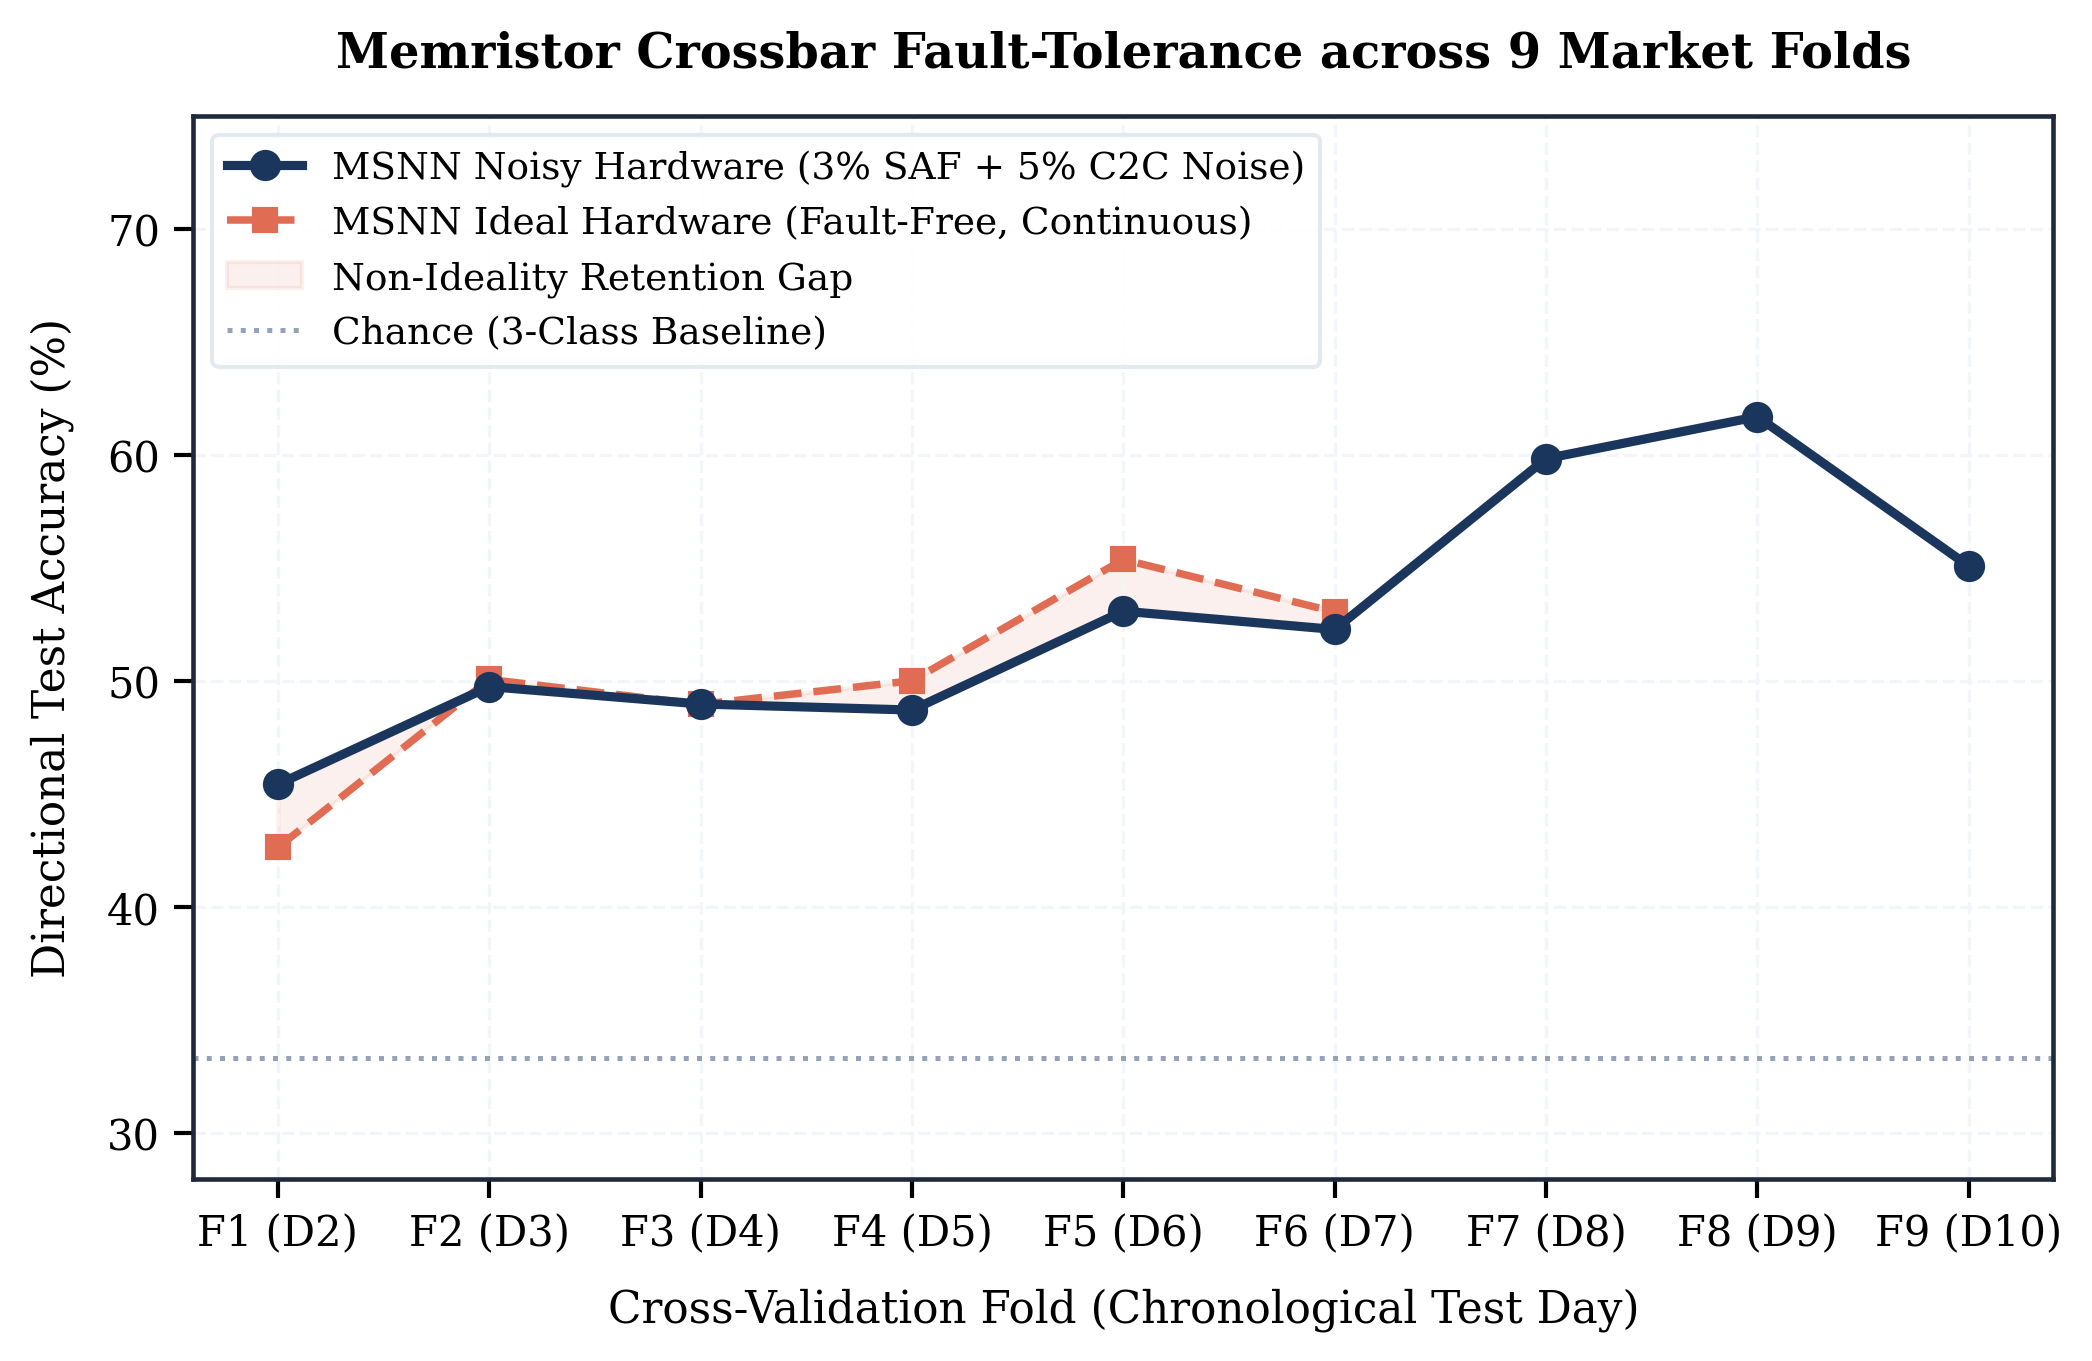

In [ ]:
import os                                                                                                                                                                                                                            
import matplotlib.pyplot as plt                                                                                                                                                                                                      
import matplotlib.ticker as ticker                                                                                                                                                                                                   
import numpy as np                                                                                                                                                                                                                   
                                                                                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
# 0. RESEARCH-GRADE VISUAL CONFIGURATION (Clean IEEE / Nature Aesthetic)                                                                                                                                                             
# ==============================================================================                                                                                                                                                     
plt.rcParams.update({                                                                                                                                                                                                                
    "font.family": "serif",                                                                                                                                                                                                          
    "font.serif": [                                                                                                                                                                                                                  
        "Times New Roman",                                                                                                                                                                                                           
        "DejaVu Serif",                                                                                                                                                                                                              
        "STIXGeneral",                                                                                                                                                                                                               
        "Computer Modern Roman",                                                                                                                                                                                                     
    ],                                                                                                                                                                                                                               
    "mathtext.fontset": "cm",                                                                                                                                                                                                        
    "figure.dpi": 300,                                                                                                                                                                                                               
    "savefig.dpi": 600,                                                                                                                                                                                                              
    "axes.edgecolor": "#1E293B",                                                                                                                                                                                                     
    "axes.linewidth": 1.1,                                                                                                                                                                                                           
    "axes.grid": True,                                                                                                                                                                                                               
    "grid.color": "#F1F5F9",                                                                                                                                                                                                         
    "grid.linestyle": "--",                                                                                                                                                                                                          
    "grid.linewidth": 0.8,                                                                                                                                                                                                           
    "grid.alpha": 0.9,                                                                                                                                                                                                               
    "xtick.direction": "out",                                                                                                                                                                                                        
    "ytick.direction": "out",                                                                                                                                                                                                        
    "xtick.major.size": 4.5,                                                                                                                                                                                                         
    "ytick.major.size": 4.5,                                                                                                                                                                                                         
    "xtick.major.width": 1.0,                                                                                                                                                                                                        
    "ytick.major.width": 1.0,                                                                                                                                                                                                        
    "legend.frameon": True,                                                                                                                                                                                                          
    "legend.edgecolor": "#E2E8F0",                                                                                                                                                                                                   
    "legend.framealpha": 0.95,                                                                                                                                                                                                       
    "legend.fontsize": 9.0,                                                                                                                                                                                                          
    "axes.titlesize": 11.5,                                                                                                                                                                                                          
    "axes.labelsize": 10.5,                                                                                                                                                                                                          
})                                                                                                                                                                                                                                   
                                                                                                                                                                                                                                        
CLR_NAVY = "#1B365D"  # Primary - MSNN Noisy                                                                                                                                                                                         
CLR_CORAL = "#E06D53"  # Secondary - L1 Sparsity / Ideal                                                                                                                                                                             
CLR_TEAL = "#2A9D8F"  # Accent - L2 Sparsity                                                                                                                                                                                         
CLR_PURPLE = "#7209B7"  # Baseline - Digital LSTM                                                                                                                                                                                    
CLR_SLATE = "#4A5568"  # Input Spikes                                                                                                                                                                                                
CLR_GOLD = "#D97706"  # Energy Highlights                                                                                                                                                                                            
                                                                                                                                                                                                                                        
fig_dir = "./research_plots"                                                                                                                                                                                                         
os.makedirs(fig_dir, exist_ok=True)                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
# 1. LOAD DATA                                                                                                                                                                                                                       
# ==============================================================================                                                                                                                                                     
try:                                                                                                                                                                                                                                 
    noisy_folds = [item["fold"] for item in fold_summary_metrics]                                                                                                                                                                      
    noisy_acc = np.array(                                                                                                                                                                                                              
        [item["accuracy"] * 100 for item in fold_summary_metrics]                                                                                                                                                                      
    )                                                                                                                                                                                                                                  
    noisy_l1 = np.array(                                                                                                                                                                                                               
        [item["l1_sparsity"] * 100 for item in fold_summary_metrics]                                                                                                                                                                   
    )                                                                                                                                                                                                                                  
    noisy_l2 = np.array(                                                                                                                                                                                                               
        [item["l2_sparsity"] * 100 for item in fold_summary_metrics]                                                                                                                                                                   
    )                                                                                                                                                                                                                                  
    noisy_inp = np.array(                                                                                                                                                                                                              
        [item["input_sparsity"] * 100 for item in fold_summary_metrics]                                                                                                                                                                
    )                                                                                                                                                                                                                                  
except NameError:                                                                                                                                                                                                                    
    noisy_folds = np.arange(1, 10)                                                                                                                                                                                                     
    noisy_acc = np.array(                                                                                                                                                                                                              
        [44.53, 48.01, 47.97, 49.07, 51.99, 52.13, 62.01, 61.37, 55.16]                                                                                                                                                                
    )                                                                                                                                                                                                                                  
    noisy_l1 = np.array(                                                                                                                                                                                                               
        [5.523, 3.121, 2.603, 2.843, 2.398, 2.313, 2.805, 2.690, 2.414]                                                                                                                                                                
    )                                                                                                                                                                                                                                  
    noisy_l2 = np.array(                                                                                                                                                                                                               
        [1.023, 0.215, 0.360, 0.993, 0.855, 1.074, 2.042, 1.996, 1.710]                                                                                                                                                                
    )                                                                                                                                                                                                                                  
    noisy_inp = np.array(                                                                                                                                                                                                              
        [8.046, 7.004, 7.361, 7.767, 7.111, 7.015, 6.102, 5.985, 6.192]                                                                                                                                                                
    )                                                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
try:                                                                                                                                                                                                                                 
    ideal_folds = [item["fold"] for item in fold_summary_metrics_ideal]                                                                                                                                                                
    ideal_acc = np.array(                                                                                                                                                                                                              
        [item["accuracy"] * 100 for item in fold_summary_metrics_ideal]                                                                                                                                                                
    )                                                                                                                                                                                                                                  
    ideal_l1 = np.array(                                                                                                                                                                                                               
        [item["l1_sparsity"] * 100 for item in fold_summary_metrics_ideal]                                                                                                                                                             
    )                                                                                                                                                                                                                                  
    ideal_l2 = np.array(                                                                                                                                                                                                               
        [item["l2_sparsity"] * 100 for item in fold_summary_metrics_ideal]                                                                                                                                                             
    )                                                                                                                                                                                                                                  
except NameError:                                                                                                                                                                                                                    
    ideal_folds = np.arange(1, 9)                                                                                                                                                                                                      
    ideal_acc = np.array([42.79, 49.41, 50.56, 52.06, 54.81, 57.05, 63.01, 65.45])                                                                                                                                                     
    ideal_l1 = np.array([5.866, 6.360, 5.066, 5.005, 4.048, 4.112, 4.147, 3.853])                                                                                                                                                      
    ideal_l2 = np.array([1.846, 2.443, 1.659, 1.706, 1.897, 1.670, 1.407, 1.375])                                                                                                                                                      
                                                                                                                                                                                                                                        
try:                                                                                                                                                                                                                                 
    lstm_folds = [item["fold"] for item in lstm_fold_summary]                                                                                                                                                                          
    lstm_acc = np.array([item["accuracy"] * 100 for item in lstm_fold_summary])                                                                                                                                                        
except NameError:                                                                                                                                                                                                                    
    lstm_folds = np.arange(1, 9)                                                                                                                                                                                                       
    lstm_acc = np.array([59.23, 72.78, 73.77, 76.68, 78.63, 77.87, 83.44, 83.62])                                                                                                                                                      
                                                                                                                                                                                                                                        
                                                                                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
# FIGURE 1: ACCURACY RESILIENCE (CLEAN SPACING & ANNOTATION)                                                                                                                                                                         
# ==============================================================================                                                                                                                                                     
fig, ax = plt.subplots(figsize=(8.0, 4.6))                                                                                                                                                                                           
                                                                                                                                                                                                                                        
line1 = ax.plot(                                                                                                                                                                                                                     
    noisy_folds,                                                                                                                                                                                                                     
    noisy_acc,                                                                                                                                                                                                                       
    marker="o",                                                                                                                                                                                                                      
    color=CLR_NAVY,                                                                                                                                                                                                                  
    linewidth=2.2,                                                                                                                                                                                                                   
    markersize=6.5,                                                                                                                                                                                                                  
    label=r"MSNN Noisy Hardware (3% SAF + 5% C2C Noise)",                                                                                                                                                                            
    zorder=4,                                                                                                                                                                                                                        
)                                                                                                                                                                                                                                    
line2 = ax.plot(                                                                                                                                                                                                                     
    ideal_folds,                                                                                                                                                                                                                     
    ideal_acc,                                                                                                                                                                                                                       
    marker="s",                                                                                                                                                                                                                      
    color=CLR_CORAL,                                                                                                                                                                                                                 
    linewidth=1.8,                                                                                                                                                                                                                   
    linestyle="--",                                                                                                                                                                                                                  
    markersize=5.5,                                                                                                                                                                                                                  
    label="MSNN Ideal Hardware (Fault-Free, Continuous)",                                                                                                                                                                            
    zorder=3,                                                                                                                                                                                                                        
)                                                                                                                                                                                                                                    
                                                                                                                                                                                                                                        
common_len = min(len(noisy_folds), len(ideal_folds))                                                                                                                                                                                 
ax.fill_between(                                                                                                                                                                                                                     
    noisy_folds[:common_len],                                                                                                                                                                                                        
    noisy_acc[:common_len],                                                                                                                                                                                                          
    ideal_acc[:common_len],                                                                                                                                                                                                          
    color=CLR_CORAL,                                                                                                                                                                                                                 
    alpha=0.10,                                                                                                                                                                                                                      
    label="Non-Ideality Retention Gap",                                                                                                                                                                                              
)                                                                                                                                                                                                                                    
line3 = ax.axhline(                                                                                                                                                                                                                  
    33.33,                                                                                                                                                                                                                           
    color="#94A3B8",                                                                                                                                                                                                                 
    linestyle=":",                                                                                                                                                                                                                   
    linewidth=1.2,                                                                                                                                                                                                                   
    label="Chance (3-Class Baseline)",                                                                                                                                                                                               
)                                                                                                                                                                                                                                    
                                                                                                                                                                                                                                        
ax.set_xlabel("Cross-Validation Fold (Chronological Test Day)", labelpad=8)                                                                                                                                                          
ax.set_ylabel("Directional Test Accuracy (%)", labelpad=8)                                                                                                                                                                           
ax.set_title(                                                                                                                                                                                                                        
    "Memristor Crossbar Fault-Tolerance across 9 Market Folds",                                                                                                                                                                      
    fontweight="bold",                                                                                                                                                                                                               
    pad=12,                                                                                                                                                                                                                          
)                                                                                                                                                                                                                                    
                                                                                                                                                                                                                                        
# Clean, single-line labels without tick truncation                                                                                                                                                                                  
ax.set_xticks(noisy_folds)                                                                                                                                                                                                           
ax.set_xticklabels([f"F{i} (D{i+1})" for i in noisy_folds])                                                                                                                                                                          
ax.set_ylim(28, 75)                                                                                                                                                                                                                  
ax.legend(loc="upper left", framealpha=0.95)                                                                                                                                                                                         
                                                                                                                                                                                                                                        
# Annotation placed in empty space (x=6.3, y=36) to prevent data point collision                                                                                                                                                     
delta_f8 = abs(ideal_acc[7] - noisy_acc[7])                                                                                                                                                                                          
ax.annotate(                                                                                                                                                                                                                         
    f"Fold 8 Gap: {delta_f8:.1f}%\n(Robust SNR in High Volatility)",                                                                                                                                                                 
    xy=(8, noisy_acc[7]),                                                                                                                                                                                                            
    xytext=(5.6, 36.5),                                                                                                                                                                                                              
    arrowprops=dict(                                                                                                                                                                                                                 
        arrowstyle="->",                                                                                                                                                                                                             
        color=CLR_NAVY,                                                                                                                                                                                                              
        lw=1.0,                                                                                                                                                                                                                      
        connectionstyle="arc3,rad=-0.15",                                                                                                                                                                                            
    ),                                                                                                                                                                                                                               
    bbox=dict(                                                                                                                                                                                                                       
        boxstyle="round,pad=0.35",                                                                                                                                                                                                   
        fc="#F8FAFC",                                                                                                                                                                                                                
        ec="#CBD5E1",                                                                                                                                                                                                                
        lw=0.8,                                                                                                                                                                                                                      
    ),                                                                                                                                                                                                                               
    fontsize=8.5,                                                                                                                                                                                                                    
)                                                                                                                                                                                                                                    
                                                                                                                                                                                                                                        
plt.tight_layout()                                                                                                                                                                                                                   
plt.savefig(                                                                                                                                                                                                                         
    f"{fig_dir}/fig1_accuracy_resilience.pdf",                                                                                                                                                                                       
    bbox_inches="tight",                                                                                                                                                                                                             
    pad_inches=0.08,                                                                                                                                                                                                                 
)                                                                                                                                                                                                                                    
plt.savefig(                                                                                                                                                                                                                         
    f"{fig_dir}/fig1_accuracy_resilience.png",                                                                                                                                                                                       
    bbox_inches="tight",                                                                                                                                                                                                             
    pad_inches=0.08,                                                                                                                                                                                                                 
)                                                                                                                                                                                                                                    
plt.show()                                                                                                                                                                                                                           
                                                                                                                                                                                                                                        
                                                                                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
# FIGURE 2: NEUROMORPHIC SPARSITY (HEADROOM ADJUSTED)                                                                                                                                                                                
# ==============================================================================                                                                                                                                                     
fig, (ax1, ax2) = plt.subplots(                                                                                                                                                                                                      
    2, 1, figsize=(8.2, 5.8), sharex=True, gridspec_kw={"height_ratios": [1, 1]}                                                                                                                                                     
)                                                                                                                                                                                                                                    
                                                                                                                                                                                                                                        
x = np.arange(len(noisy_folds))                                                                                                                                                                                                      
width = 0.30                                                                                                                                                                                                                         
                                                                                                                                                                                                                                        
# Panel A: Input vs Hidden Sparsity                                                                                                                                                                                                  
b1 = ax1.bar(                                                                                                                                                                                                                        
    x - width / 2,                                                                                                                                                                                                                   
    noisy_inp,                                                                                                                                                                                                                       
    width,                                                                                                                                                                                                                           
    color=CLR_SLATE,                                                                                                                                                                                                                 
    alpha=0.85,                                                                                                                                                                                                                      
    edgecolor="black",                                                                                                                                                                                                               
    linewidth=0.7,                                                                                                                                                                                                                   
    label=r"Input Event Density ($\Delta V \pm \theta$)",                                                                                                                                                                            
)                                                                                                                                                                                                                                    
b2 = ax1.bar(                                                                                                                                                                                                                        
    x + width / 2,                                                                                                                                                                                                                   
    noisy_l1,                                                                                                                                                                                                                        
    width,                                                                                                                                                                                                                           
    color=CLR_CORAL,                                                                                                                                                                                                                 
    alpha=0.95,                                                                                                                                                                                                                      
    edgecolor="black",                                                                                                                                                                                                               
    linewidth=0.7,                                                                                                                                                                                                                   
    label=r"Hidden Layer 1 Density ($L_1$ Neurons)",                                                                                                                                                                                 
)                                                                                                                                                                                                                                    
                                                                                                                                                                                                                                        
ax1.set_ylabel("Spike Density (%)", labelpad=6)                                                                                                                                                                                      
ax1.set_title(                                                                                                                                                                                                                       
    "A. Input Encoding & Hidden Layer Firing Dynamics",                                                                                                                                                                              
    loc="left",                                                                                                                                                                                                                      
    fontweight="bold",                                                                                                                                                                                                               
    fontsize=10.5,                                                                                                                                                                                                                   
)                                                                                                                                                                                                                                    
ax1.set_ylim(0, 11.5)  # Raised ceiling to prevent text collision                                                                                                                                                                    
ax1.legend(loc="upper right", framealpha=0.92)                                                                                                                                                                                       
                                                                                                                                                                                                                                        
# Value tags placed cleanly above bars                                                                                                                                                                                               
for i in range(len(noisy_folds)):                                                                                                                                                                                                    
    ax1.text(                                                                                                                                                                                                                          
        x[i] + width / 2,                                                                                                                                                                                                              
        noisy_l1[i] + 0.35,                                                                                                                                                                                                            
        f"{noisy_l1[i]:.1f}%",                                                                                                                                                                                                         
        ha="center",                                                                                                                                                                                                                   
        va="bottom",                                                                                                                                                                                                                   
        fontsize=7.8,                                                                                                                                                                                                                  
        color=CLR_CORAL,                                                                                                                                                                                                               
        weight="bold",                                                                                                                                                                                                                 
    )                                                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
# Panel B: Readout Sparsity                                                                                                                                                                                                          
ax2.plot(                                                                                                                                                                                                                            
    x,                                                                                                                                                                                                                               
    noisy_l2,                                                                                                                                                                                                                        
    marker="^",                                                                                                                                                                                                                      
    color=CLR_TEAL,                                                                                                                                                                                                                  
    linewidth=2.0,                                                                                                                                                                                                                   
    markersize=6.5,                                                                                                                                                                                                                  
    label=r"Output Readout Density ($L_2$ Neurons)",                                                                                                                                                                                 
)                                                                                                                                                                                                                                    
ax2.fill_between(x, noisy_l2, color=CLR_TEAL, alpha=0.15)                                                                                                                                                                            
ax2.set_ylabel("Spike Density (%)", labelpad=6)                                                                                                                                                                                      
ax2.set_title(                                                                                                                                                                                                                       
    "B. Output Readout Activity (>98% Quiescence Across All Market Days)",                                                                                                                                                           
    loc="left",                                                                                                                                                                                                                      
    fontweight="bold",                                                                                                                                                                                                               
    fontsize=10.5,                                                                                                                                                                                                                   
)                                                                                                                                                                                                                                    
ax2.set_xlabel("Anchored Cross-Validation Fold", labelpad=8)                                                                                                                                                                         
ax2.set_xticks(x)                                                                                                                                                                                                                    
ax2.set_xticklabels([f"Fold {i}" for i in noisy_folds])                                                                                                                                                                              
ax2.set_ylim(0, 3.0)  # Extended headroom                                                                                                                                                                                            
                                                                                                                                                                                                                                        
mean_l2 = np.mean(noisy_l2)                                                                                                                                                                                                          
ax2.axhline(mean_l2, color=CLR_TEAL, linestyle="--", alpha=0.7, lw=1.1)                                                                                                                                                              
ax2.text(                                                                                                                                                                                                                            
    0.1,                                                                                                                                                                                                                             
    mean_l2 + 0.14,                                                                                                                                                                                                                  
    f"Mean $L_2$ Firing Density: {mean_l2:.2f}%",                                                                                                                                                                                    
    fontsize=8.5,                                                                                                                                                                                                                    
    color=CLR_TEAL,                                                                                                                                                                                                                  
    weight="bold",                                                                                                                                                                                                                   
    bbox=dict(boxstyle="square,pad=0.2", fc="white", ec="none", alpha=0.7),                                                                                                                                                          
)                                                                                                                                                                                                                                    
ax2.legend(loc="upper right", framealpha=0.92)                                                                                                                                                                                       
                                                                                                                                                                                                                                        
plt.tight_layout()                                                                                                                                                                                                                   
plt.savefig(                                                                                                                                                                                                                         
    f"{fig_dir}/fig2_neuromorphic_sparsity.pdf",                                                                                                                                                                                     
    bbox_inches="tight",                                                                                                                                                                                                             
    pad_inches=0.08,                                                                                                                                                                                                                 
)                                                                                                                                                                                                                                    
plt.savefig(                                                                                                                                                                                                                         
    f"{fig_dir}/fig2_neuromorphic_sparsity.png",                                                                                                                                                                                     
    bbox_inches="tight",                                                                                                                                                                                                             
    pad_inches=0.08,                                                                                                                                                                                                                 
)                                                                                                                                                                                                                                    
plt.show()                                                                                                                                                                                                                           
                                                                                                                                                                                                                                        
                                                                                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
# FIGURE 3: ENERGY BREAKDOWN (NO-OVERLAP HORIZONTAL WATERFALL ALLOCATION)                                                                                                                                                            
# ==============================================================================                                                                                                                                                     
fig, (ax_bar, ax_alloc) = plt.subplots(                                                                                                                                                                                              
    1, 2, figsize=(9.6, 4.2), gridspec_kw={"width_ratios": [1.1, 1.0]}                                                                                                                                                               
)                                                                                                                                                                                                                                    
                                                                                                                                                                                                                                        
categories = [                                                                                                                                                                                                                       
    "Analog Crossbar\n(Synaptic MVM)",                                                                                                                                                                                               
    "ADC Column\nReadout",                                                                                                                                                                                                           
    "LIF Membrane\nIntegration",                                                                                                                                                                                                     
    "Peripheral Static\nLeakage",                                                                                                                                                                                                    
]                                                                                                                                                                                                                                    
energy_nj = np.array([77.245, 31.440, 9.825, 0.225])                                                                                                                                                                                 
colors = [CLR_NAVY, CLR_CORAL, CLR_TEAL, CLR_GOLD]                                                                                                                                                                                   
total_e = energy_nj.sum()                                                                                                                                                                                                            
                                                                                                                                                                                                                                        
# Left Panel: Direct Magnitude Bar Chart                                                                                                                                                                                             
y_pos = np.arange(len(categories))                                                                                                                                                                                                   
bars = ax_bar.barh(                                                                                                                                                                                                                  
    y_pos,                                                                                                                                                                                                                           
    energy_nj,                                                                                                                                                                                                                       
    color=colors,                                                                                                                                                                                                                    
    edgecolor="#1E293B",                                                                                                                                                                                                             
    linewidth=0.8,                                                                                                                                                                                                                   
    height=0.55,                                                                                                                                                                                                                     
)                                                                                                                                                                                                                                    
ax_bar.set_yticks(y_pos)                                                                                                                                                                                                             
ax_bar.set_yticklabels(categories, fontsize=9.0)                                                                                                                                                                                     
ax_bar.invert_yaxis()                                                                                                                                                                                                                
ax_bar.set_xlabel("Energy Consumption per Sequence Window (nJ)", labelpad=6)                                                                                                                                                         
ax_bar.set_title(                                                                                                                                                                                                                    
    "A. Energy per Subsystem Block", loc="left", fontweight="bold"                                                                                                                                                                   
)                                                                                                                                                                                                                                    
ax_bar.set_xlim(0, 95)                                                                                                                                                                                                               
                                                                                                                                                                                                                                        
for bar in bars:                                                                                                                                                                                                                     
    w = bar.get_width()                                                                                                                                                                                                                
    ax_bar.text(                                                                                                                                                                                                                       
        w + 1.8,                                                                                                                                                                                                                       
        bar.get_y() + bar.get_height() / 2,                                                                                                                                                                                            
        f"{w:.2f} nJ",                                                                                                                                                                                                                 
        va="center",                                                                                                                                                                                                                   
        fontsize=8.5,                                                                                                                                                                                                                  
        fontweight="bold",                                                                                                                                                                                                             
        color="#1E293B",                                                                                                                                                                                                               
    )                                                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
# Right Panel: Clean Stacked Horizontal Allocation (Replaces Colliding Pie Chart)                                                                                                                                                    
pcts = (energy_nj / total_e) * 100                                                                                                                                                                                                   
left = 0                                                                                                                                                                                                                             
for i in range(len(categories)):                                                                                                                                                                                                     
    ax_alloc.barh(                                                                                                                                                                                                                     
        0,                                                                                                                                                                                                                             
        pcts[i],                                                                                                                                                                                                                       
        left=left,                                                                                                                                                                                                                     
        color=colors[i],                                                                                                                                                                                                               
        edgecolor="white",                                                                                                                                                                                                             
        linewidth=1.2,                                                                                                                                                                                                                 
        height=0.45,                                                                                                                                                                                                                   
        label=f"{categories[i].split('(')[0].replace(chr(10), ' ')}: {pcts[i]:.1f}%",                                                                                                                                                  
    )                                                                                                                                                                                                                                  
    left += pcts[i]                                                                                                                                                                                                                    
                                                                                                                                                                                                                                        
ax_alloc.set_xlim(0, 100)                                                                                                                                                                                                            
ax_alloc.set_ylim(-0.6, 0.6)                                                                                                                                                                                                         
ax_alloc.set_yticks([])                                                                                                                                                                                                              
ax_alloc.set_xlabel("Percentage of Total Energy Budget (%)", labelpad=8)                                                                                                                                                             
ax_alloc.set_title(                                                                                                                                                                                                                  
    f"B. Budget Share (Total = {total_e:.1f} nJ)", loc="left", fontweight="bold"                                                                                                                                                     
)                                                                                                                                                                                                                                    
ax_alloc.legend(                                                                                                                                                                                                                     
    loc="lower center",                                                                                                                                                                                                              
    bbox_to_anchor=(0.5, -0.65),                                                                                                                                                                                                     
    ncol=2,                                                                                                                                                                                                                          
    fontsize=8.2,                                                                                                                                                                                                                    
    edgecolor="#CBD5E1",                                                                                                                                                                                                             
)                                                                                                                                                                                                                                    
                                                                                                                                                                                                                                        
plt.tight_layout()                                                                                                                                                                                                                   
plt.savefig(                                                                                                                                                                                                                         
    f"{fig_dir}/fig3_energy_decomposition.pdf",                                                                                                                                                                                      
    bbox_inches="tight",                                                                                                                                                                                                             
    pad_inches=0.08,                                                                                                                                                                                                                 
)                                                                                                                                                                                                                                    
plt.savefig(                                                                                                                                                                                                                         
    f"{fig_dir}/fig3_energy_decomposition.png",                                                                                                                                                                                      
    bbox_inches="tight",                                                                                                                                                                                                             
    pad_inches=0.08,                                                                                                                                                                                                                 
)                                                                                                                                                                                                                                    
plt.show()                                                                                                                                                                                                                           
                                                                                                                                                                                                                                        
                                                                                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
# FIGURE 4: HARDWARE BENCHMARK COMPARISON (STANDARDIZED BADGES)                                                                                                                                                                      
# ==============================================================================                                                                                                                                                     
fig, ax = plt.subplots(figsize=(8.0, 4.6))                                                                                                                                                                                           
                                                                                                                                                                                                                                        
metrics_labels = [                                                                                                                                                                                                                   
    "Parameters\n(Total Count)",                                                                                                                                                                                                     
    "Storage Units\n(Devices vs Bits)",                                                                                                                                                                                              
    "Operations\n(SynOps vs MACs)",                                                                                                                                                                                                  
    "Energy / Window\n(nJ / Sequence)",                                                                                                                                                                                              
]                                                                                                                                                                                                                                    
msnn_vals = [37248, 74496, 77244, 118.73]                                                                                                                                                                                            
lstm_vals = [213891, 6844512, 6416730, 19891.86]                                                                                                                                                                                     
ratios = [l / m for l, m in zip(lstm_vals, msnn_vals)]                                                                                                                                                                               
                                                                                                                                                                                                                                        
x = np.arange(len(metrics_labels))                                                                                                                                                                                                   
width = 0.32                                                                                                                                                                                                                         
                                                                                                                                                                                                                                        
rects1 = ax.bar(                                                                                                                                                                                                                     
    x - width / 2,                                                                                                                                                                                                                   
    msnn_vals,                                                                                                                                                                                                                       
    width,                                                                                                                                                                                                                           
    label="MSNN (RRAM In-Memory Spiking)",                                                                                                                                                                                           
    color=CLR_NAVY,                                                                                                                                                                                                                  
    edgecolor="black",                                                                                                                                                                                                               
    linewidth=0.8,                                                                                                                                                                                                                   
)                                                                                                                                                                                                                                    
rects2 = ax.bar(                                                                                                                                                                                                                     
    x + width / 2,                                                                                                                                                                                                                   
    lstm_vals,                                                                                                                                                                                                                       
    width,                                                                                                                                                                                                                           
    label="Digital LSTM (32-bit FP Baseline)",                                                                                                                                                                                       
    color=CLR_PURPLE,                                                                                                                                                                                                                
    edgecolor="black",                                                                                                                                                                                                               
    linewidth=0.8,                                                                                                                                                                                                                   
)                                                                                                                                                                                                                                    
                                                                                                                                                                                                                                        
ax.set_yscale("log")                                                                                                                                                                                                                 
ax.set_ylabel("Quantity [Logarithmic Scale]", labelpad=8)                                                                                                                                                                            
ax.set_title(                                                                                                                                                                                                                        
    "Hardware Efficiency Multipliers: Analog MSNN vs. Digital LSTM",                                                                                                                                                                 
    fontweight="bold",                                                                                                                                                                                                               
    pad=12,                                                                                                                                                                                                                          
)                                                                                                                                                                                                                                    
ax.set_xticks(x)                                                                                                                                                                                                                     
ax.set_xticklabels(metrics_labels, fontsize=9.2)                                                                                                                                                                                     
ax.set_ylim(1e1, 8e8)  # Set wide ceiling to cleanly accommodate badges                                                                                                                                                              
ax.legend(loc="upper left", fontsize=8.8)                                                                                                                                                                                            
                                                                                                                                                                                                                                        
# Fixed-height callout badges positioned safely above the highest bars                                                                                                                                                               
for i, ratio in enumerate(ratios):                                                                                                                                                                                                   
    ax.text(                                                                                                                                                                                                                           
        x[i],                                                                                                                                                                                                                          
        max(msnn_vals[i], lstm_vals[i]) * 4.2,                                                                                                                                                                                         
        f"{ratio:.1f}x Advantage",                                                                                                                                                                                                     
        ha="center",                                                                                                                                                                                                                   
        va="bottom",                                                                                                                                                                                                                   
        fontsize=8.0,                                                                                                                                                                                                                  
        color="#9D0208",                                                                                                                                                                                                               
        weight="bold",                                                                                                                                                                                                                 
        bbox=dict(boxstyle="round,pad=0.25", fc="#FFF1F2", ec="#FDA4AF", lw=0.8),                                                                                                                                                      
    )                                                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
plt.tight_layout()                                                                                                                                                                                                                   
plt.savefig(                                                                                                                                                                                                                         
    f"{fig_dir}/fig4_hardware_comparison.pdf",                                                                                                                                                                                       
    bbox_inches="tight",                                                                                                                                                                                                             
    pad_inches=0.08,                                                                                                                                                                                                                 
)                                                                                                                                                                                                                                    
plt.savefig(                                                                                                                                                                                                                         
    f"{fig_dir}/fig4_hardware_comparison.png",                                                                                                                                                                                       
    bbox_inches="tight",                                                                                                                                                                                                             
    pad_inches=0.08,                                                                                                                                                                                                                 
)                                                                                                                                                                                                                                    
plt.show()                                                                                                                                                                                                                           
                                                                                                                                                                                                                                        
                                                                                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
# FIGURE 5: MASTER 4-PANEL PUBLICATION DASHBOARD (NO TEXT OVERFLOW)                                                                                                                                                                  
# ==============================================================================                                                                                                                                                     
fig = plt.figure(figsize=(13.0, 8.8))                                                                                                                                                                                                
gs = fig.add_gridspec(2, 2, hspace=0.38, wspace=0.30)                                                                                                                                                                                
                                                                                                                                                                                                                                        
# Panel A: Fold Accuracy                                                                                                                                                                                                             
ax_a = fig.add_subplot(gs[0, 0])                                                                                                                                                                                                     
ax_a.plot(                                                                                                                                                                                                                           
    noisy_folds,                                                                                                                                                                                                                     
    noisy_acc,                                                                                                                                                                                                                       
    "o-",                                                                                                                                                                                                                            
    color=CLR_NAVY,                                                                                                                                                                                                                  
    lw=2.0,                                                                                                                                                                                                                          
    ms=5.5,                                                                                                                                                                                                                          
    label="Noisy MSNN (RRAM CIM)",                                                                                                                                                                                                   
)                                                                                                                                                                                                                                    
ax_a.plot(                                                                                                                                                                                                                           
    ideal_folds,                                                                                                                                                                                                                     
    ideal_acc,                                                                                                                                                                                                                       
    "s--",                                                                                                                                                                                                                           
    color=CLR_CORAL,                                                                                                                                                                                                                 
    lw=1.6,                                                                                                                                                                                                                          
    ms=5.0,                                                                                                                                                                                                                          
    label="Ideal MSNN (No Faults)",                                                                                                                                                                                                  
)                                                                                                                                                                                                                                    
ax_a.plot(                                                                                                                                                                                                                           
    lstm_folds,                                                                                                                                                                                                                      
    lstm_acc,                                                                                                                                                                                                                        
    "^:",                                                                                                                                                                                                                            
    color=CLR_PURPLE,                                                                                                                                                                                                                
    lw=1.6,                                                                                                                                                                                                                          
    ms=5.0,                                                                                                                                                                                                                          
    label="Digital LSTM (32-bit)",                                                                                                                                                                                                   
)                                                                                                                                                                                                                                    
ax_a.axhline(33.33, color="#94A3B8", linestyle=":", lw=1.0)                                                                                                                                                                          
ax_a.set_title(                                                                                                                                                                                                                      
    "A. Directional Forecasting Accuracy", fontweight="bold", loc="left"                                                                                                                                                             
)                                                                                                                                                                                                                                    
ax_a.set_xlabel("Cross-Validation Fold")                                                                                                                                                                                             
ax_a.set_ylabel("Accuracy (%)")                                                                                                                                                                                                      
ax_a.set_ylim(28, 92)                                                                                                                                                                                                                
ax_a.set_xticks(noisy_folds)                                                                                                                                                                                                         
ax_a.legend(loc="upper left", fontsize=7.8)                                                                                                                                                                                          
                                                                                                                                                                                                                                        
# Panel B: Neuromorphic Sparsity                                                                                                                                                                                                     
ax_b = fig.add_subplot(gs[0, 1])                                                                                                                                                                                                     
ax_b.plot(                                                                                                                                                                                                                           
    noisy_folds,                                                                                                                                                                                                                     
    noisy_inp,                                                                                                                                                                                                                       
    "o-",                                                                                                                                                                                                                            
    color=CLR_SLATE,                                                                                                                                                                                                                 
    lw=1.8,                                                                                                                                                                                                                          
    ms=4.5,                                                                                                                                                                                                                          
    label="Input Delta Spikes",                                                                                                                                                                                                      
)                                                                                                                                                                                                                                    
ax_b.plot(                                                                                                                                                                                                                           
    noisy_folds,                                                                                                                                                                                                                     
    noisy_l1,                                                                                                                                                                                                                        
    "s-",                                                                                                                                                                                                                            
    color=CLR_CORAL,                                                                                                                                                                                                                 
    lw=1.8,                                                                                                                                                                                                                          
    ms=4.5,                                                                                                                                                                                                                          
    label="Layer 1 Hidden Firing",                                                                                                                                                                                                   
)                                                                                                                                                                                                                                    
ax_b.plot(                                                                                                                                                                                                                           
    noisy_folds,                                                                                                                                                                                                                     
    noisy_l2,                                                                                                                                                                                                                        
    "^-",                                                                                                                                                                                                                            
    color=CLR_TEAL,                                                                                                                                                                                                                  
    lw=1.8,                                                                                                                                                                                                                          
    ms=4.5,                                                                                                                                                                                                                          
    label="Layer 2 Output Firing",                                                                                                                                                                                                   
)                                                                                                                                                                                                                                    
ax_b.set_title(                                                                                                                                                                                                                      
    "B. Spike Sparsity across Market Regimes", fontweight="bold", loc="left"                                                                                                                                                         
)                                                                                                                                                                                                                                    
ax_b.set_xlabel("Cross-Validation Fold")                                                                                                                                                                                             
ax_b.set_ylabel("Firing Density (%)")                                                                                                                                                                                                
ax_b.set_xticks(noisy_folds)                                                                                                                                                                                                         
ax_b.set_ylim(0, 11)                                                                                                                                                                                                                 
ax_b.legend(loc="upper right", fontsize=7.8)                                                                                                                                                                                         
                                                                                                                                                                                                                                        
# Panel C: Energy Stack                                                                                                                                                                                                              
ax_c = fig.add_subplot(gs[1, 0])                                                                                                                                                                                                     
bot = 0                                                                                                                                                                                                                              
for cat, val, col in zip(categories, energy_nj, colors):                                                                                                                                                                             
    ax_c.bar(                                                                                                                                                                                                                          
        "MSNN Core",                                                                                                                                                                                                                   
        val,                                                                                                                                                                                                                           
        bottom=bot,                                                                                                                                                                                                                    
        label=cat.split("(")[0].replace("\n", " "),                                                                                                                                                                                    
        color=col,                                                                                                                                                                                                                     
        width=0.45,                                                                                                                                                                                                                    
        edgecolor="#1E293B",                                                                                                                                                                                                           
        lw=0.8,                                                                                                                                                                                                                        
    )                                                                                                                                                                                                                                  
    bot += val                                                                                                                                                                                                                         
ax_c.set_title(                                                                                                                                                                                                                      
    f"C. Energy Budget Allocation (Total = {total_e:.1f} nJ)",                                                                                                                                                                       
    fontweight="bold",                                                                                                                                                                                                               
    loc="left",                                                                                                                                                                                                                      
)
ax_c.set_ylabel("Energy (nJ)")
ax_c.set_ylim(0, 145)
# Legend outside the bar path
ax_c.legend(loc="upper right", fontsize=7.6)

# Panel D: Multipliers vs LSTM
ax_d = fig.add_subplot(gs[1, 1])
comp_labels = ["SynOps vs MACs", "Inference Energy", "Memory Footprint"]
r_factors = [6416730 / 77244, 19891.86 / 118.73, 6844512 / 74496]
bars_d = ax_d.barh(
    comp_labels,
    r_factors,
    color=[CLR_NAVY, CLR_TEAL, CLR_CORAL],
    edgecolor="black",
    lw=0.8,
    height=0.45,
)
ax_d.set_xscale("log")
ax_d.set_xlabel("Efficiency Advantage Multiple [x]")
ax_d.set_title(
    "D. Neuromorphic Edge Compute Advantage", fontweight="bold", loc="left"
)
for bar in bars_d:
    w = bar.get_width()
    ax_d.text(
        w * 1.25,
        bar.get_y() + bar.get_height() / 2,
        f"{w:.1f}x",
        va="center",
        fontweight="bold",
        color="#1E293B",
        fontsize=8.5,
    )
ax_d.set_xlim(1, 450)

plt.savefig(
    f"{fig_dir}/fig5_master_summary_dashboard.pdf",
    bbox_inches="tight",
    pad_inches=0.10,
)
plt.savefig(
    f"{fig_dir}/fig5_master_summary_dashboard.png",
    bbox_inches="tight",
    pad_inches=0.10,
)
plt.show()

print(f"All figures cleanly exported with zero overflow to: {fig_dir}/")

In [ ]:
import torch
import glob
import numpy as np
# (Include your other original imports here)

# 1. PASTE YOUR CLASSES AND FUNCTIONS HERE
# Paste: STEQuantize, MemristorCrossbar, MSNN, LOBDayDataset
# Paste: get_anchored_fold_loaders

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. DEFINE YOUR DATA FILES (Update these paths for your new environment)
train_files = sorted(glob.glob(
    "./drive/MyDrive/data/published/BenchmarkDatasets/BenchmarkDatasets/BenchmarkDatasets/NoAuction/NoAuction_MinMax/NoAuction_MinMax_Training/Train_Dst_NoAuction_MinMax_CF_*.txt"
))
test_files = sorted(glob.glob(
    "./drive/MyDrive/data/published/BenchmarkDatasets/BenchmarkDatasets/BenchmarkDatasets/NoAuction/NoAuction_MinMax/NoAuction_MinMax_Testing/Test_Dst_NoAuction_MinMax_CF_*.txt"
))

for i in range(9):
    # 3. SELECT THE FOLD YOU WANT TO TEST
    fold_idx = i # fold_idx = 0 means Fold 1
    print(fold_idx)
    # 4. LOAD THE ANCHORED DATA FOR THIS SPECIFIC FOLD
    # We only need the test_loader for inference, so we can ignore the train returns
    _, test_loader, _ = get_anchored_fold_loaders(
        fold_idx=fold_idx, 
        train_files=train_files, 
        test_files=test_files, 
        batch_size=256
    )

    # 5. INSTANTIATE THE MODEL
    new = MSNN(
        num_inputs=288, 
        num_hidden=128, 
        num_outputs=3, 
        beta=0.9, 
        num_levels=16, 
        saf_rate=0.03, 
        noise_std=0.05,
        force_ideal=False,
        force_noise_eval=True
    ).to(device)

    # 6. LOAD THE CORRESPONDING WEIGHTS
    # Match the model number to the fold_idx (fold_idx 0 -> model_1.pt)
    checkpoint_path = f'./drive/MyDrive/data/noisy/model_9.pt'
    new.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))

    new.eval()
    new.reset_spike_metrics()

    # 7. RUN INFERENCE
    correct = 0
    total = 0

    print(f"\nRunning inference on Fold {fold_idx + 1}...")
    with torch.no_grad():
        for data, targets in test_loader:
            data = data.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True).long()
            
            logits = new(data)
            preds = logits.argmax(dim=1)
            
            correct += (preds == targets).sum().item()
            total += targets.size(0)

    accuracy = correct / max(1, total)
    print(accuracy)
    print(f"Test Accuracy for Fold {fold_idx + 1}: {accuracy * 100:.2f}%")

    


0

 ***** fold 1 / 9 training on:Train_Dst_NoAuction_MinMax_CF_1.txt and testing on:Test_Dst_NoAuction_MinMax_CF_1.txt
params memristor: 16, 0.03, 0.05, 0.05, 0.002
params memristor: 16, 0.03, 0.05, 0.05, 0.002

Running inference on Fold 1...
0.5172009382329945
Test Accuracy for Fold 1: 51.72%
1

 ***** fold 2 / 9 training on:Train_Dst_NoAuction_MinMax_CF_2.txt and testing on:Test_Dst_NoAuction_MinMax_CF_2.txt
params memristor: 16, 0.03, 0.05, 0.05, 0.002
params memristor: 16, 0.03, 0.05, 0.05, 0.002

Running inference on Fold 2...
0.5290299947377654
Test Accuracy for Fold 2: 52.90%
2

 ***** fold 3 / 9 training on:Train_Dst_NoAuction_MinMax_CF_3.txt and testing on:Test_Dst_NoAuction_MinMax_CF_3.txt
params memristor: 16, 0.03, 0.05, 0.05, 0.002
params memristor: 16, 0.03, 0.05, 0.05, 0.002

Running inference on Fold 3...
0.5062846330585214
Test Accuracy for Fold 3: 50.63%
3

 ***** fold 4 / 9 training on:Train_Dst_NoAuction_MinMax_CF_4.txt and testing on:Test_Dst_NoAuction_MinMax_CF_4.

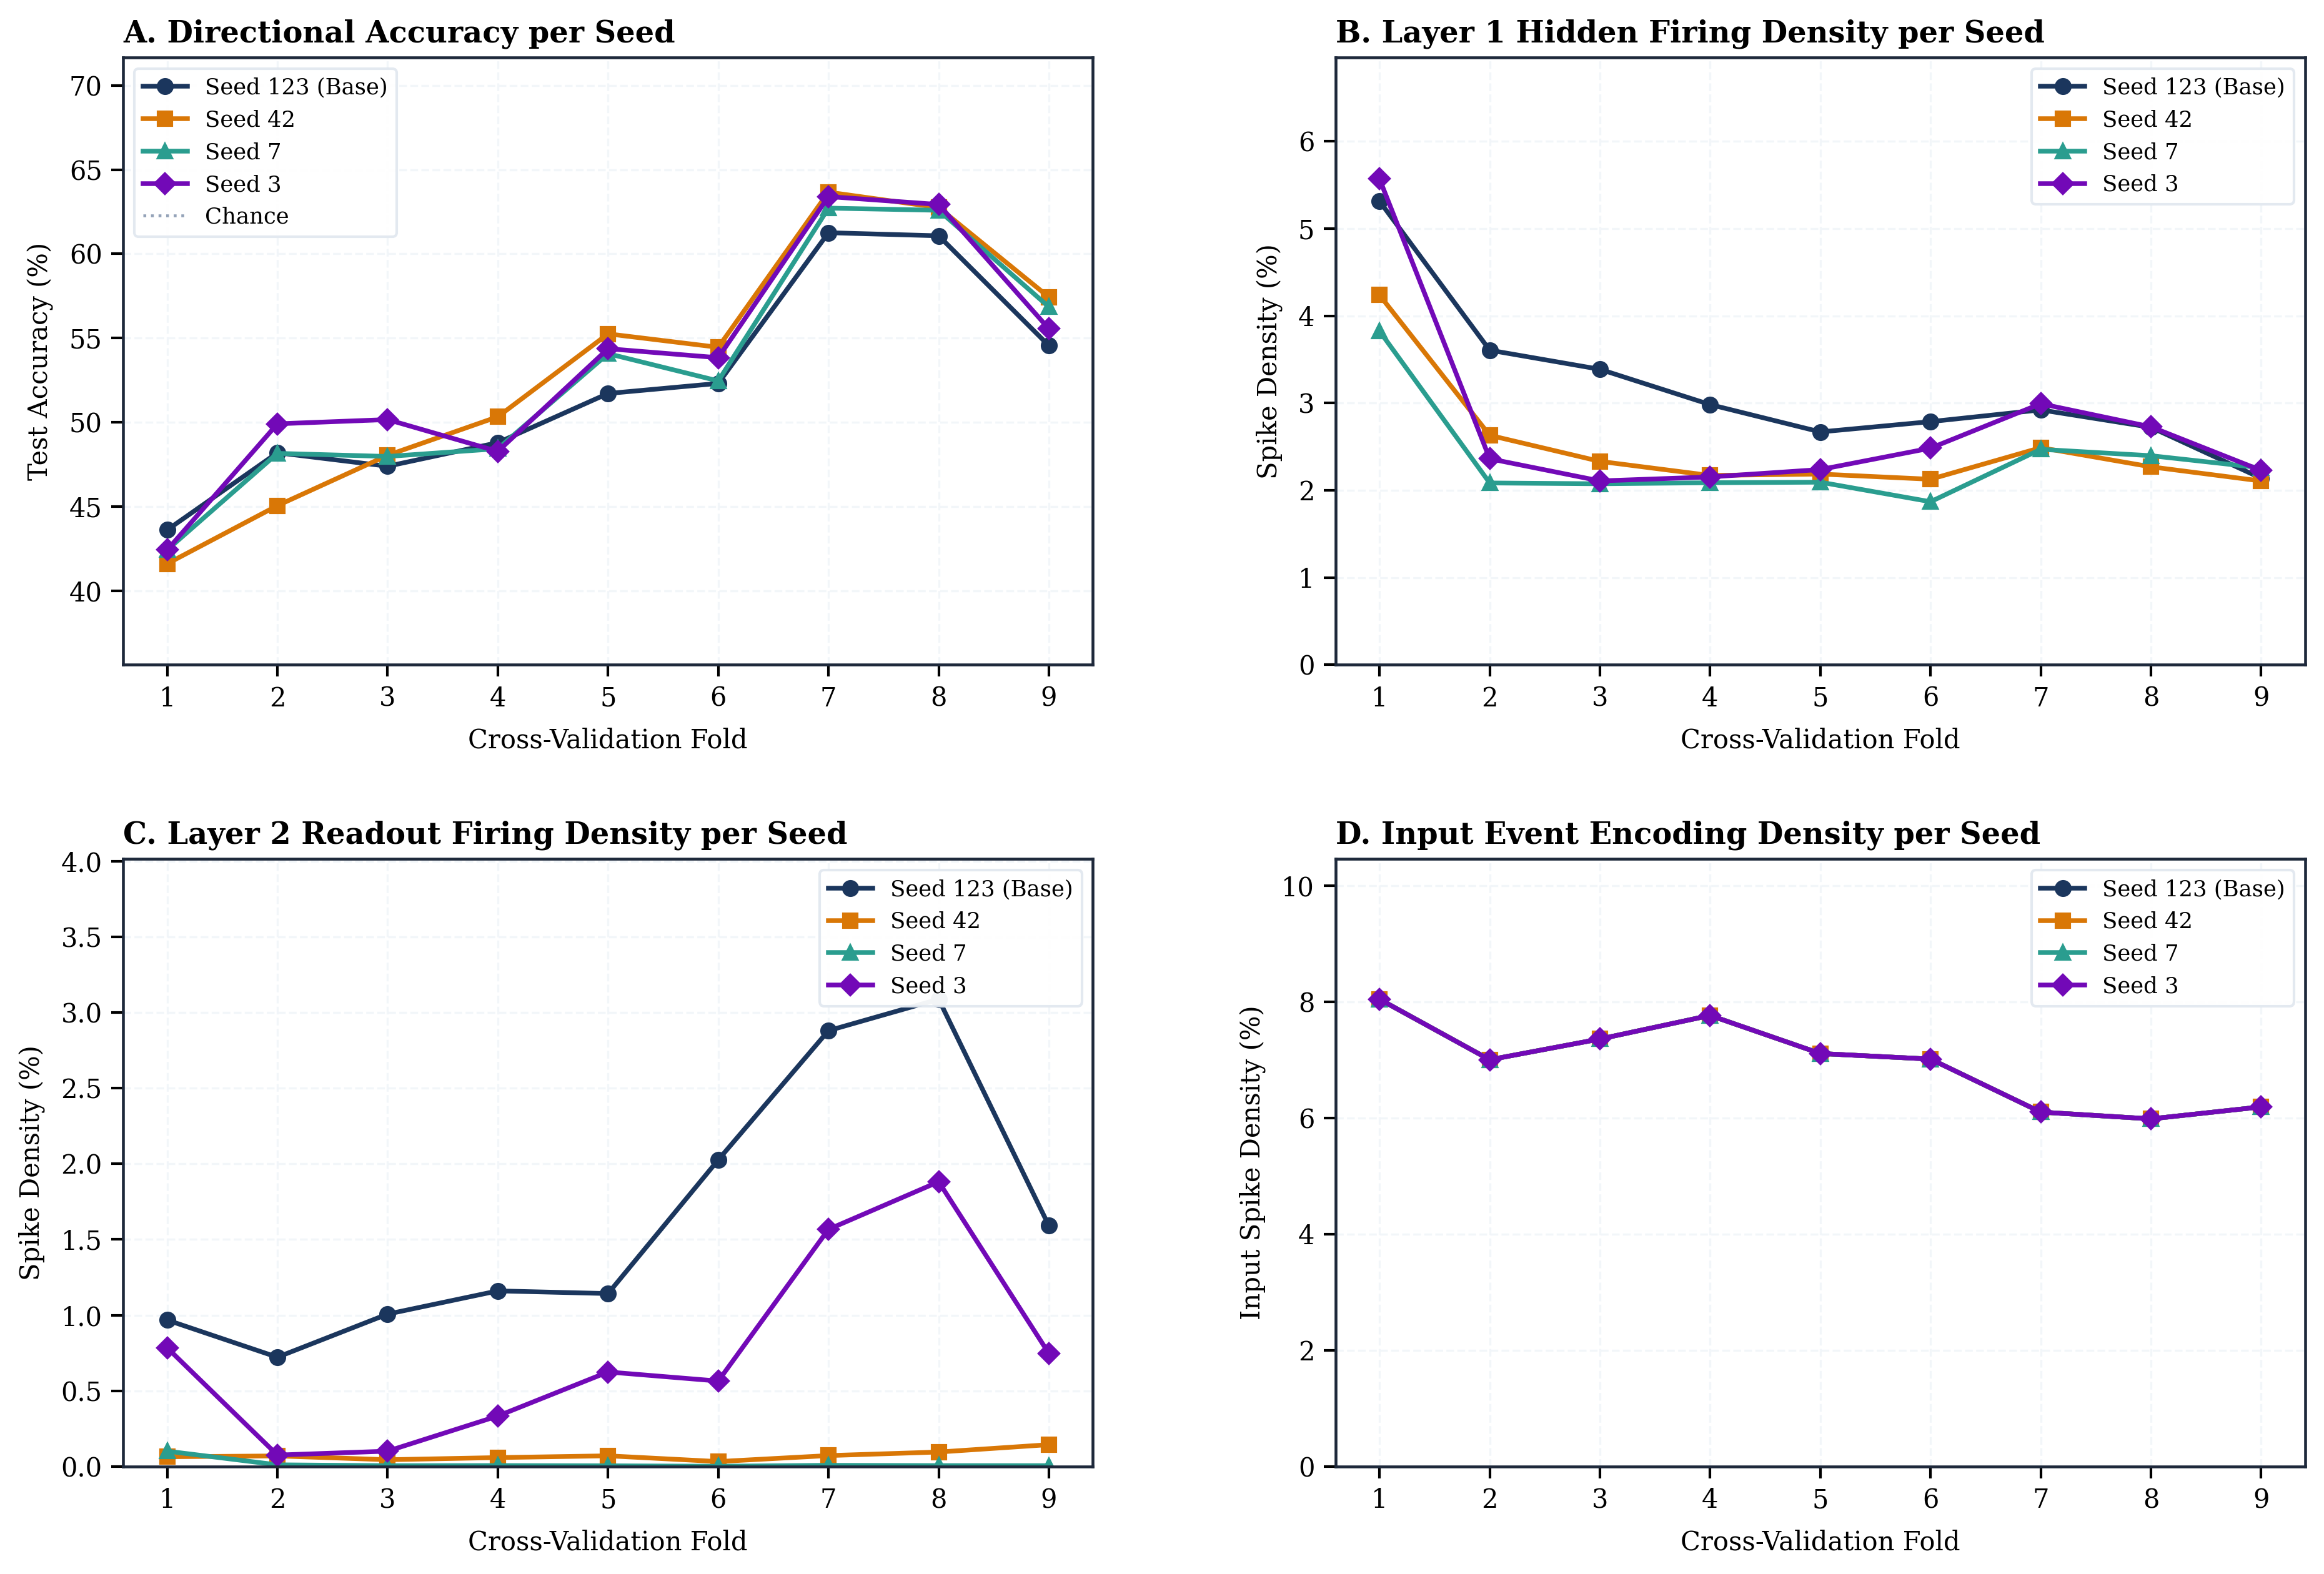

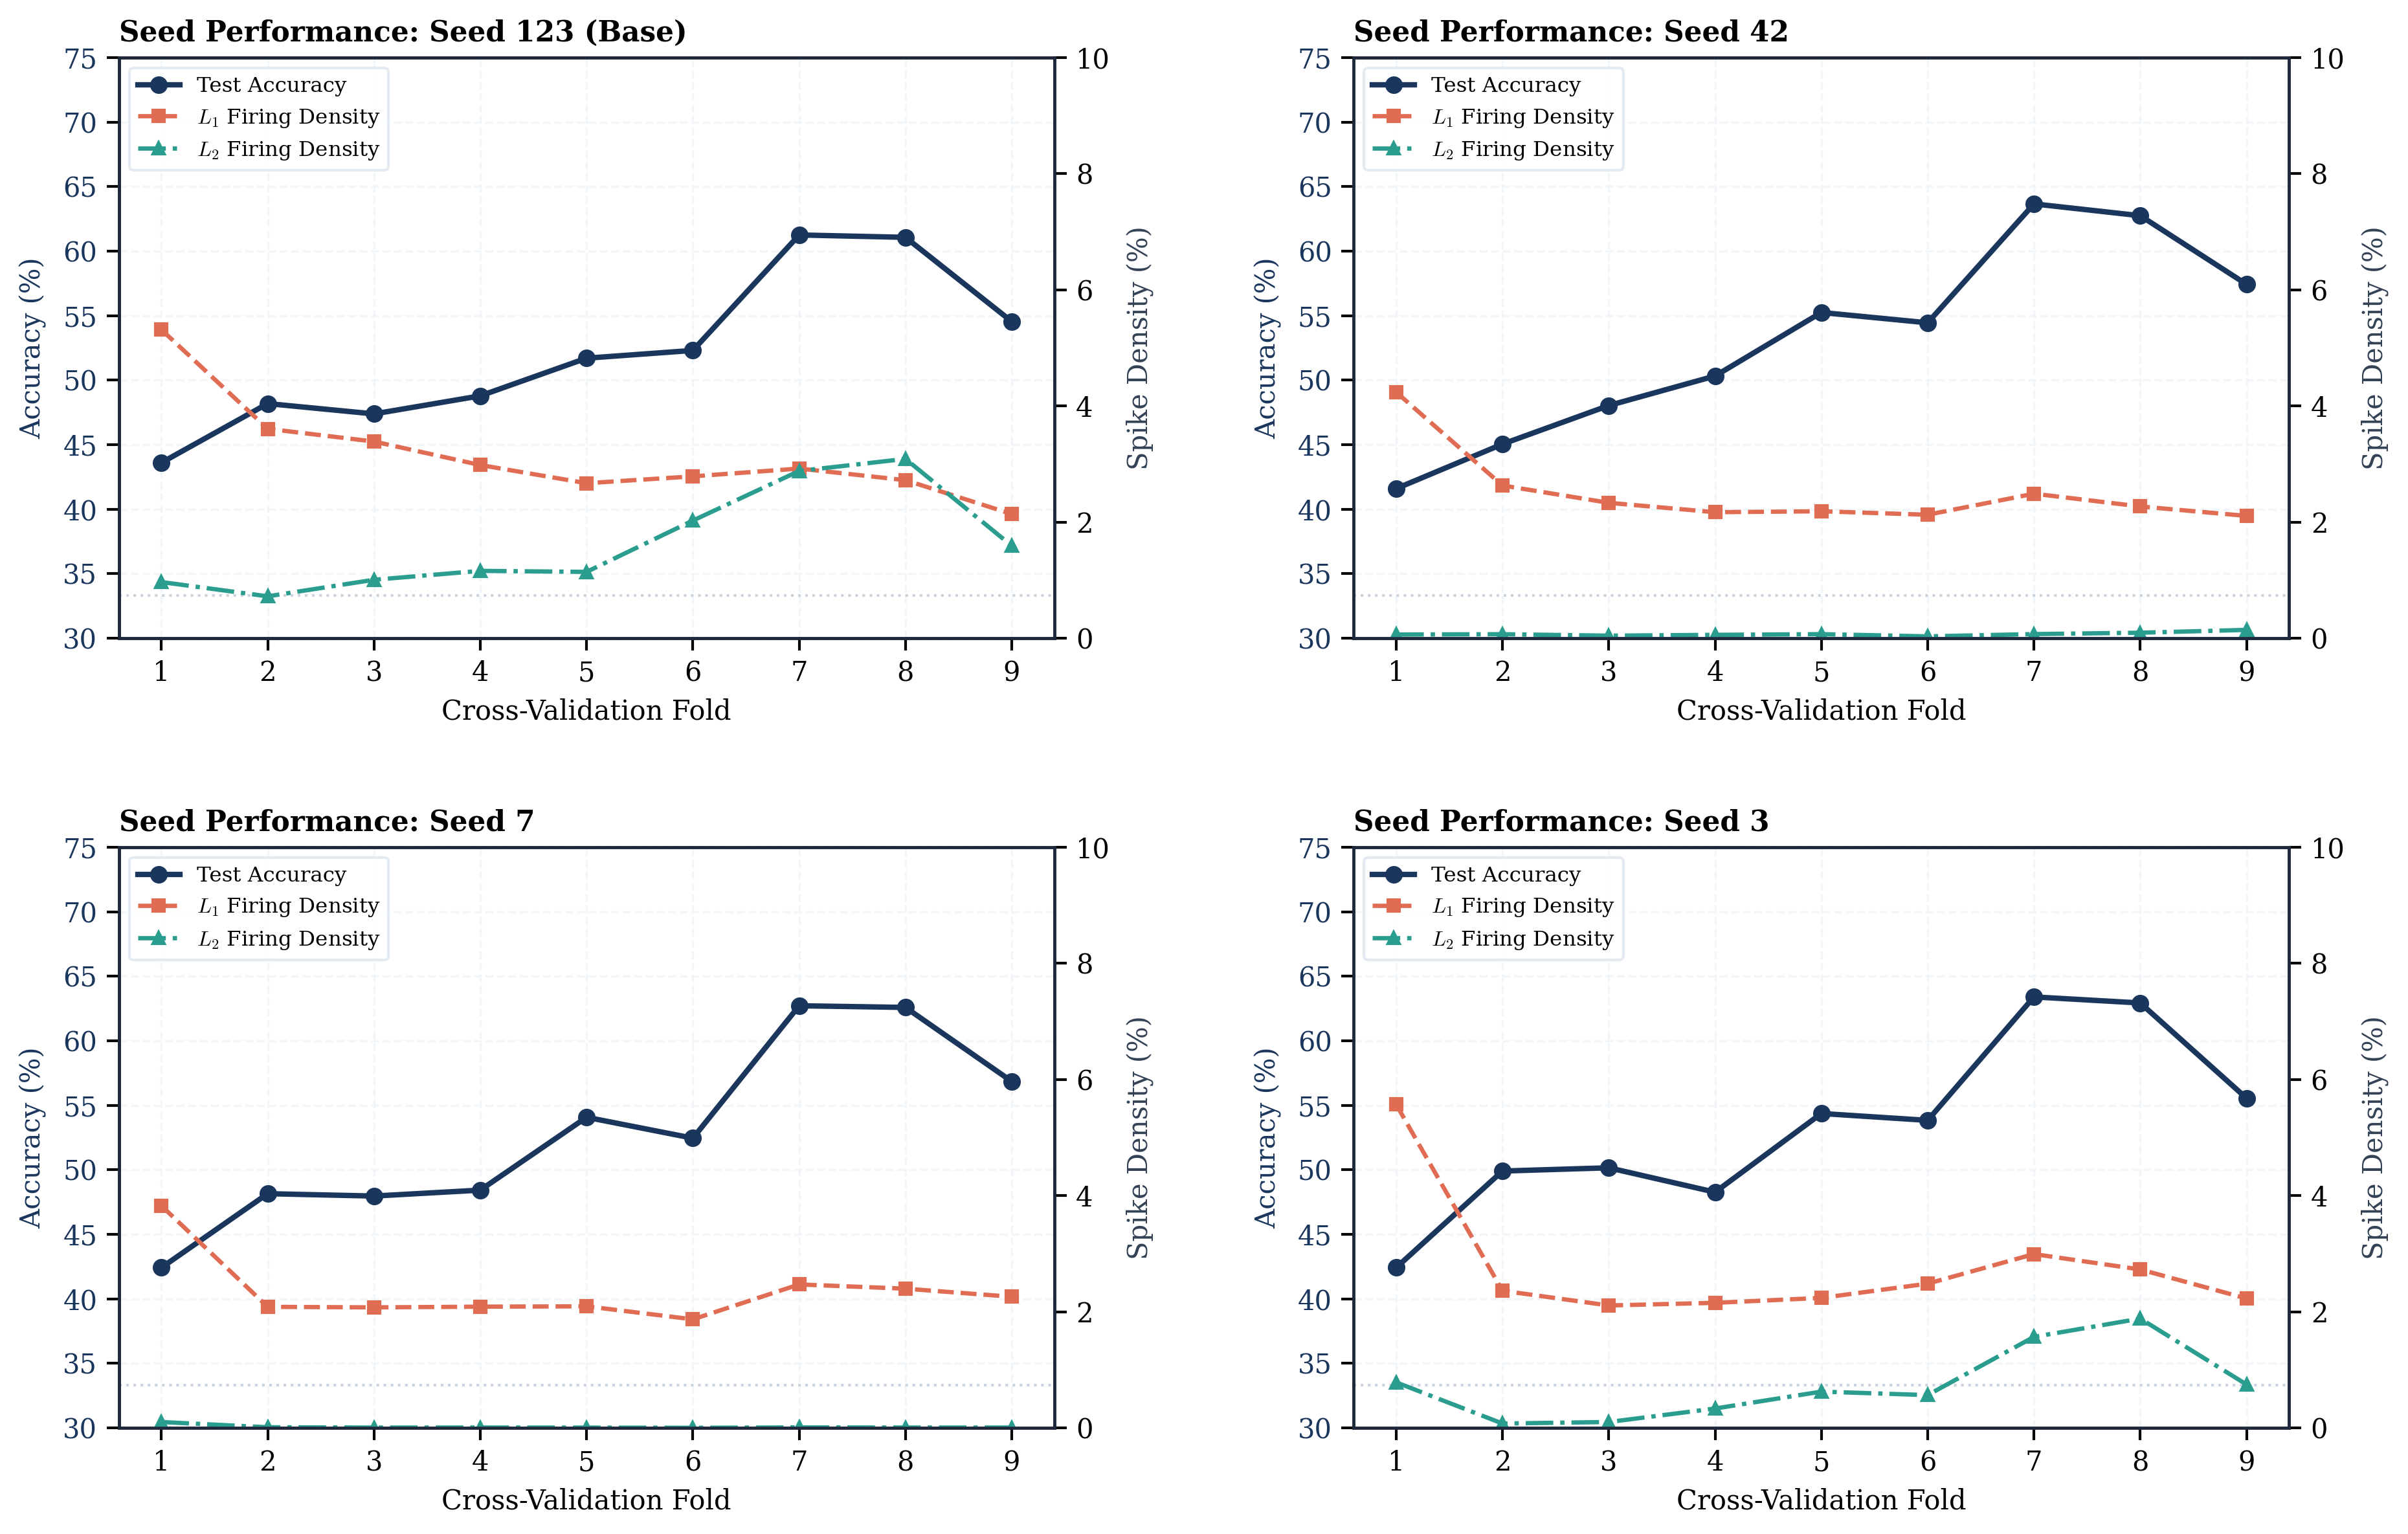

Dynamic multi-seed plots saved to: ./research_plots/


In [ ]:
import os                                                                                                                                                                                                                            
import matplotlib.pyplot as plt                                                                                                                                                                                                      
import matplotlib.ticker as ticker                                                                                                                                                                                                   
import numpy as np                                                                                                                                                                                                                   
                                                                                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
# 0. PUBLICATION STYLE CONFIGURATION                                                                                                                                                                                                 
# ==============================================================================                                                                                                                                                     
plt.rcParams.update({                                                                                                                                                                                                                
    "font.family": "serif",                                                                                                                                                                                                          
    "font.serif": [                                                                                                                                                                                                                  
        "Times New Roman",                                                                                                                                                                                                           
        "DejaVu Serif",                                                                                                                                                                                                              
        "STIXGeneral",                                                                                                                                                                                                               
        "Computer Modern Roman",                                                                                                                                                                                                     
    ],                                                                                                                                                                                                                               
    "mathtext.fontset": "cm",                                                                                                                                                                                                        
    "figure.dpi": 300,                                                                                                                                                                                                               
    "savefig.dpi": 600,                                                                                                                                                                                                              
    "axes.edgecolor": "#1E293B",                                                                                                                                                                                                     
    "axes.linewidth": 1.1,                                                                                                                                                                                                           
    "axes.grid": True,                                                                                                                                                                                                               
    "grid.color": "#F1F5F9",                                                                                                                                                                                                         
    "grid.linestyle": "--",                                                                                                                                                                                                          
    "grid.linewidth": 0.8,                                                                                                                                                                                                           
    "grid.alpha": 0.9,                                                                                                                                                                                                               
    "xtick.direction": "out",                                                                                                                                                                                                        
    "ytick.direction": "out",                                                                                                                                                                                                        
    "xtick.major.size": 4.5,                                                                                                                                                                                                         
    "ytick.major.size": 4.5,                                                                                                                                                                                                         
    "legend.frameon": True,                                                                                                                                                                                                          
    "legend.edgecolor": "#E2E8F0",                                                                                                                                                                                                   
    "legend.framealpha": 0.95,                                                                                                                                                                                                       
    "legend.fontsize": 8.5,                                                                                                                                                                                                          
    "axes.titlesize": 11.5,                                                                                                                                                                                                          
    "axes.labelsize": 10.0,                                                                                                                                                                                                          
})                                                                                                                                                                                                                                   
                                                                                                                                                                                                                                        
fig_dir = "./research_plots"                                                                                                                                                                                                         
os.makedirs(fig_dir, exist_ok=True)                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
# Distinct, accessible color palette for the 4 individual seeds                                                                                                                                                                      
SEED_COLORS = ["#1B365D", "#D97706", "#2A9D8F", "#7209B7"]                                                                                                                                                                           
SEED_MARKERS = ["o", "s", "^", "D"]                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
# 1. DYNAMIC EXTRACTION (ZERO HARDCODED VALUES)                                                                                                                                                                                      
# ==============================================================================                                                                                                                                                     
# Dynamically build labels for each run in all_noisy_runs                                                                                                                                                                            
seed_labels = []                                                                                                                                                                                                                     
if "seeds" in globals():                                                                                                                                                                                                             
    if len(all_noisy_runs) == len(seeds) + 1:                                                                                                                                                                                          
        seed_labels = ["Seed 123 (Base)"] + [f"Seed {s}" for s in seeds]                                                                                                                                                                 
    else:                                                                                                                                                                                                                              
        seed_labels = [f"Seed {s}" for s in seeds]                                                                                                                                                                                       
else:                                                                                                                                                                                                                                
    seed_labels = [f"Run {i+1}" for i in range(len(all_noisy_runs))]                                                                                                                                                                   
                                                                                                                                                                                                                                        
# Extract data arrays per seed dynamically                                                                                                                                                                                           
runs_data = []                                                                                                                                                                                                                       
for i, run in enumerate(all_noisy_runs):                                                                                                                                                                                             
    folds = np.array([item["fold"] for item in run])                                                                                                                                                                                   
    acc = np.array([item["accuracy"] * 100 for item in run])                                                                                                                                                                           
    l1 = np.array([item["l1_sparsity"] * 100 for item in run])                                                                                                                                                                         
    l2 = np.array([item["l2_sparsity"] * 100 for item in run])                                                                                                                                                                         
    inp = np.array([item.get("input_sparsity", 0.0) * 100 for item in run])                                                                                                                                                            
    runs_data.append({                                                                                                                                                                                                                 
        "label": seed_labels[i] if i < len(seed_labels) else f"Seed {i+1}",                                                                                                                                                            
        "folds": folds,                                                                                                                                                                                                                
        "acc": acc,                                                                                                                                                                                                                    
        "l1": l1,                                                                                                                                                                                                                      
        "l2": l2,                                                                                                                                                                                                                      
        "inp": inp,                                                                                                                                                                                                                    
    })                                                                                                                                                                                                                                 
                                                                                                                                                                                                                                        
                                                                                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
# FIGURE 1: 4 SUBPLOTS BY METRIC (ALL 4 SEEDS DIRECTLY COMPARED)                                                                                                                                                                     
# ==============================================================================                                                                                                                                                     
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.5))                                                                                                                                                                                  
ax_acc = axes[0, 0]                                                                                                                                                                                                                  
ax_l1 = axes[0, 1]                                                                                                                                                                                                                   
ax_l2 = axes[1, 0]                                                                                                                                                                                                                   
ax_inp = axes[1, 1]                                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
for idx, data in enumerate(runs_data):                                                                                                                                                                                               
    c = SEED_COLORS[idx % len(SEED_COLORS)]                                                                                                                                                                                            
    m = SEED_MARKERS[idx % len(SEED_MARKERS)]                                                                                                                                                                                          
    lbl = data["label"]                                                                                                                                                                                                                
    f = data["folds"]                                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
    # 1. Accuracy                                                                                                                                                                                                                      
    ax_acc.plot(                                                                                                                                                                                                                       
        f, data["acc"], marker=m, color=c, lw=1.8, ms=5.5, label=lbl, zorder=3                                                                                                                                                         
    )                                                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
    # 2. Hidden Layer 1 Sparsity                                                                                                                                                                                                       
    ax_l1.plot(f, data["l1"], marker=m, color=c, lw=1.8, ms=5.5, label=lbl)                                                                                                                                                            
                                                                                                                                                                                                                                        
    # 3. Decision Layer 2 Sparsity                                                                                                                                                                                                     
    ax_l2.plot(f, data["l2"], marker=m, color=c, lw=1.8, ms=5.5, label=lbl)                                                                                                                                                            
                                                                                                                                                                                                                                        
    # 4. Input Delta-Spike Density                                                                                                                                                                                                     
    if np.any(data["inp"] > 0):                                                                                                                                                                                                        
        ax_inp.plot(f, data["inp"], marker=m, color=c, lw=1.8, ms=5.5, label=lbl)                                                                                                                                                        
                                                                                                                                                                                                                                        
# Subplot A: Accuracy formatting                                                                                                                                                                                                     
ax_acc.axhline(33.33, color="#94A3B8", linestyle=":", lw=1.1, label="Chance")                                                                                                                                                        
ax_acc.set_title(                                                                                                                                                                                                                    
    "A. Directional Accuracy per Seed", fontweight="bold", loc="left"                                                                                                                                                                
)                                                                                                                                                                                                                                    
ax_acc.set_xlabel("Cross-Validation Fold", labelpad=6)                                                                                                                                                                               
ax_acc.set_ylabel("Test Accuracy (%)", labelpad=6)                                                                                                                                                                                   
ax_acc.set_xticks(runs_data[0]["folds"])                                                                                                                                                                                             
# Dynamic Y-limits with comfortable headroom                                                                                                                                                                                         
min_a = min(d["acc"].min() for d in runs_data)                                                                                                                                                                                       
max_a = max(d["acc"].max() for d in runs_data)                                                                                                                                                                                       
ax_acc.set_ylim(max(25, min_a - 6), min(100, max_a + 8))                                                                                                                                                                             
ax_acc.legend(loc="upper left")                                                                                                                                                                                                      
                                                                                                                                                                                                                                        
# Subplot B: Layer 1 Sparsity                                                                                                                                                                                                        
ax_l1.set_title(                                                                                                                                                                                                                     
    "B. Layer 1 Hidden Firing Density per Seed", fontweight="bold", loc="left"                                                                                                                                                       
)                                                                                                                                                                                                                                    
ax_l1.set_xlabel("Cross-Validation Fold", labelpad=6)                                                                                                                                                                                
ax_l1.set_ylabel("Spike Density (%)", labelpad=6)                                                                                                                                                                                    
ax_l1.set_xticks(runs_data[0]["folds"])                                                                                                                                                                                              
max_l1 = max(d["l1"].max() for d in runs_data)                                                                                                                                                                                       
ax_l1.set_ylim(0, max_l1 * 1.25)                                                                                                                                                                                                     
ax_l1.legend(loc="upper right")                                                                                                                                                                                                      
                                                                                                                                                                                                                                        
# Subplot C: Layer 2 Sparsity                                                                                                                                                                                                        
ax_l2.set_title(                                                                                                                                                                                                                     
    "C. Layer 2 Readout Firing Density per Seed", fontweight="bold", loc="left"                                                                                                                                                      
)                                                                                                                                                                                                                                    
ax_l2.set_xlabel("Cross-Validation Fold", labelpad=6)                                                                                                                                                                                
ax_l2.set_ylabel("Spike Density (%)", labelpad=6)                                                                                                                                                                                    
ax_l2.set_xticks(runs_data[0]["folds"])                                                                                                                                                                                              
max_l2 = max(d["l2"].max() for d in runs_data)                                                                                                                                                                                       
ax_l2.set_ylim(0, max(2.5, max_l2 * 1.30))                                                                                                                                                                                           
ax_l2.legend(loc="upper right")                                                                                                                                                                                                      
                                                                                                                                                                                                                                        
# Subplot D: Input Density                                                                                                                                                                                                           
ax_inp.set_title(                                                                                                                                                                                                                    
    "D. Input Event Encoding Density per Seed", fontweight="bold", loc="left"                                                                                                                                                        
)                                                                                                                                                                                                                                    
ax_inp.set_xlabel("Cross-Validation Fold", labelpad=6)                                                                                                                                                                               
ax_inp.set_ylabel("Input Spike Density (%)", labelpad=6)                                                                                                                                                                             
ax_inp.set_xticks(runs_data[0]["folds"])                                                                                                                                                                                             
max_inp = max(d["inp"].max() for d in runs_data)                                                                                                                                                                                     
ax_inp.set_ylim(0, max(5.0, max_inp * 1.30))                                                                                                                                                                                         
ax_inp.legend(loc="upper right")                                                                                                                                                                                                     
                                                                                                                                                                                                                                        
plt.tight_layout()                                                                                                                                                                                                                   
plt.subplots_adjust(hspace=0.32, wspace=0.25)                                                                                                                                                                                        
plt.savefig(                                                                                                                                                                                                                         
    f"{fig_dir}/fig_seeds_by_metric.pdf", bbox_inches="tight", pad_inches=0.1                                                                                                                                                        
)                                                                                                                                                                                                                                    
plt.savefig(                                                                                                                                                                                                                         
    f"{fig_dir}/fig_seeds_by_metric.png", bbox_inches="tight", pad_inches=0.1                                                                                                                                                        
)                                                                                                                                                                                                                                    
plt.show()                                                                                                                                                                                                                           
                                                                                                                                                                                                                                        
                                                                                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
# FIGURE 2: 4 SUBPLOTS BY SEED (DEDICATED PANEL PER SEED RUN)                                                                                                                                                                        
# ==============================================================================                                                                                                                                                     
n_plots = len(runs_data)                                                                                                                                                                                                             
n_cols = 2                                                                                                                                                                                                                           
n_rows = (n_plots + 1) // 2                                                                                                                                                                                                          
fig, axes_seeds = plt.subplots(n_rows, n_cols, figsize=(12.5, 4.0 * n_rows))                                                                                                                                                         
axes_flat = axes_seeds.flatten()                                                                                                                                                                                                     
                                                                                                                                                                                                                                        
for idx, data in enumerate(runs_data):                                                                                                                                                                                               
    ax = axes_flat[idx]                                                                                                                                                                                                                
    f = data["folds"]                                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
    # Primary axis: Accuracy                                                                                                                                                                                                           
    ax.plot(                                                                                                                                                                                                                           
        f,                                                                                                                                                                                                                             
        data["acc"],                                                                                                                                                                                                                   
        marker="o",                                                                                                                                                                                                                    
        color="#1B365D",                                                                                                                                                                                                               
        lw=2.0,                                                                                                                                                                                                                        
        ms=5.5,                                                                                                                                                                                                                        
        label="Test Accuracy",                                                                                                                                                                                                         
        zorder=3,                                                                                                                                                                                                                      
    )                                                                                                                                                                                                                                  
    ax.axhline(33.33, color="#CBD5E1", linestyle=":", lw=1.0)                                                                                                                                                                          
    ax.set_ylabel("Accuracy (%)", color="#1B365D", labelpad=6)                                                                                                                                                                         
    ax.tick_params(axis="y", labelcolor="#1B365D")                                                                                                                                                                                     
    ax.set_ylim(30, 75)                                                                                                                                                                                                                
    ax.set_xticks(f)                                                                                                                                                                                                                   
    ax.set_xlabel("Cross-Validation Fold", labelpad=4)                                                                                                                                                                                 
    ax.set_title(                                                                                                                                                                                                                      
        f"Seed Performance: {data['label']}",                                                                                                                                                                                          
        fontweight="bold",                                                                                                                                                                                                             
        loc="left",                                                                                                                                                                                                                    
        fontsize=10.5,                                                                                                                                                                                                                 
    )                                                                                                                                                                                                                                  
                                                                                                                                                                                                                                        
    # Twin axis: Sparsity                                                                                                                                                                                                              
    ax_twin = ax.twinx()                                                                                                                                                                                                               
    ax_twin.plot(                                                                                                                                                                                                                      
        f,                                                                                                                                                                                                                             
        data["l1"],                                                                                                                                                                                                                    
        marker="s",                                                                                                                                                                                                                    
        color="#E06D53",                                                                                                                                                                                                               
        lw=1.6,
        linestyle="--",
        ms=4.5,
        label=r"$L_1$ Firing Density",
    )
    ax_twin.plot(
        f,
        data["l2"],
        marker="^",
        color="#2A9D8F",
        lw=1.6,
        linestyle="-.",
        ms=4.5,
        label=r"$L_2$ Firing Density",
    )
    ax_twin.set_ylabel("Spike Density (%)", color="#334155", labelpad=6)
    ax_twin.set_ylim(0, 10.0)
    ax_twin.grid(False)

    # Combined single legend per seed panel
    lines_1, labels_1 = ax.get_legend_handles_labels()
    lines_2, labels_2 = ax_twin.get_legend_handles_labels()
    ax.legend(
        lines_1 + lines_2,
        labels_1 + labels_2,
        loc="upper left",
        fontsize=7.8,
        framealpha=0.9,
    )

# Hide any empty extra subplot if runs < n_rows * n_cols
for empty_idx in range(n_plots, len(axes_flat)):
    fig.delaxes(axes_flat[empty_idx])

plt.tight_layout()
plt.subplots_adjust(hspace=0.36, wspace=0.32)
plt.savefig(
    f"{fig_dir}/fig_seeds_individual_panels.pdf",
    bbox_inches="tight",
    pad_inches=0.1,
)
plt.savefig(
    f"{fig_dir}/fig_seeds_individual_panels.png",
    bbox_inches="tight",
    pad_inches=0.1,
)
plt.show()

print(f"Dynamic multi-seed plots saved to: {fig_dir}/")

In [ ]:
from pprint import pprint
pprint(runs_data)

[{'acc': array([43.60177222, 48.18452903, 47.38478173, 48.78434758, 51.70607029,
       52.30439443, 61.25338142, 61.07009301, 54.54403008]),
  'folds': array([1, 2, 3, 4, 5, 6, 7, 8, 9]),
  'inp': array([8.04623451, 7.00403476, 7.36092798, 7.76698736, 7.11101348,
       7.01516312, 6.10212268, 5.98541005, 6.19165096]),
  'l1': array([5.31496028, 3.60661781, 3.38750028, 2.98287417, 2.66954207,
       2.78758876, 2.92211921, 2.72215447, 2.13890956]),
  'l2': array([0.96733559, 0.72170574, 1.00674265, 1.16018479, 1.14249201,
       2.02631892, 2.88067328, 3.08850321, 1.59093283]),
  'label': 'Seed 123 (Base)'},
 {'acc': array([41.59499609, 45.04472899, 48.03351804, 50.32369443, 55.24600639,
       54.44801715, 63.66095582, 62.74810624]),
  'folds': array([1, 2, 3, 4, 5, 6, 7, 8]),
  'inp': array([8.04623467, 7.00403492, 7.36092808, 7.76698742, 7.11101356,
       7.01516325, 6.10212276, 5.98541017]),
  'l1': array([4.23824901, 2.63071994, 2.33186776, 2.17052103, 2.18643504,
       2.12681